# Análisis de la rotación de empleados

**Objetivo:** construir un modelo de regresión logística que prediga la probabilidad de que un empleado abandone la empresa (variable `Attrition`), interpretar qué factores influyen en esa decisión y evaluar el modelo con la curva ROC.

## 1. Análisis exploratorio y descriptivo

### 1.1. Carga de librerías y datos

Se cargan las librerías necesarias y el conjunto de datos. Se utiliza la codificación `utf-8-sig` porque el fichero contiene un carácter oculto (BOM) al inicio que, de lo contrario, alteraría el nombre de la primera columna (`Age`).

La carga se realiza mediante el módulo `src/data.py`, que lee la ruta desde el fichero de configuración y valida que los datos no contienen nulos, duplicados ni valores inesperados en la variable objetivo.

In [54]:
%load_ext autoreload
%autoreload 2
import sys
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Permite importar los módulos de src/ desde el notebook
sys.path.append(str(Path.cwd().parent))
from src.data import ROOT, load_config, load_raw_data

pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid')

config = load_config()
df = load_raw_data(config)

# Carpeta donde se guardan los gráficos para el informe
FIG_DIR = ROOT / config['paths']['figures']

print(f'Filas: {df.shape[0]} | Columnas: {df.shape[1]}')
df.head()

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Filas: 1470 | Columnas: 35


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,2,Female,94,3,2,Sales Executive,4,Single,5993,19479,8,Y,Yes,11,3,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,3,Male,61,2,2,Research Scientist,2,Married,5130,24907,1,Y,No,23,4,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,4,Male,92,2,1,Laboratory Technician,3,Single,2090,2396,6,Y,Yes,15,3,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,4,Female,56,3,1,Research Scientist,3,Married,2909,23159,1,Y,Yes,11,3,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,1,Male,40,3,1,Laboratory Technician,2,Married,3468,16632,9,Y,No,12,3,4,80,1,6,3,3,2,2,2,2


**Resultado:** el conjunto de datos contiene 1.470 registros y 35 variables, en línea con lo indicado en el enunciado. La validación de `src/data.py` se ha superado sin errores, lo que confirma que no hay valores nulos ni filas duplicadas y que `Attrition` solo toma los valores "Yes" y "No".

En las primeras filas ya se aprecian dos tipos de variables:
- **Categóricas en texto**, como `BusinessTravel`, `Department`, `JobRole` o `MaritalStatus`.
- **Numéricas**, que incluyen tanto magnitudes reales (`Age`, `MonthlyIncome`, `YearsAtCompany`) como escalas codificadas con números (`Education`, `EnvironmentSatisfaction`, `JobSatisfaction`), cuyo significado es ordinal.

También se observa que `EmployeeCount`, `Over18` y `StandardHours` parecen tomar siempre el mismo valor, lo que se comprueba en el siguiente apartado.

### 1.2. Estructura y calidad de los datos

Se revisa el tipo de cada variable, el número de valores distintos y un ejemplo de valor. Además, se comprueba explícitamente la ausencia de nulos y duplicados, si `EmployeeNumber` identifica de forma única a cada empleado y si existen variables constantes (con un único valor), que no aportan información al modelo.

In [55]:
print('Valores nulos totales:', df.isna().sum().sum())
print('Filas duplicadas:', df.duplicated().sum())
print('¿EmployeeNumber es único por fila?:', df['EmployeeNumber'].is_unique)

constantes = [col for col in df.columns if df[col].nunique() == 1]
print('Variables constantes:', constantes)

resumen = pd.DataFrame({
    'tipo': df.dtypes.astype(str),
    'valores_distintos': df.nunique(),
    'ejemplo': df.iloc[0]
})
resumen

Valores nulos totales: 0
Filas duplicadas: 0
¿EmployeeNumber es único por fila?: True
Variables constantes: ['EmployeeCount', 'Over18', 'StandardHours']


,tipo,valores_distintos,ejemplo
Age,int64,43,41
Attrition,object,2,Yes
BusinessTravel,object,3,Travel_Rarely
DailyRate,int64,886,1102
Department,object,3,Sales
DistanceFromHome,int64,29,1
Education,int64,5,2
EducationField,object,6,Life Sciences
EmployeeCount,int64,1,1
EmployeeNumber,int64,1470,1


**Resultado:**
- No hay valores nulos ni filas duplicadas, por lo que no es necesario imputar ni eliminar registros.
- `EmployeeNumber` toma un valor distinto en cada fila: es un identificador del empleado y no aporta información predictiva, así que se eliminará.
- `EmployeeCount`, `Over18` y `StandardHours` son constantes (un único valor en todo el dataset) y también se eliminarán.

En cuanto a los tipos, 26 variables se almacenan como numéricas (`int64`) y 9 como texto (`object`). Sin embargo, el tipo almacenado no coincide siempre con el tipo estadístico:
- Varias variables numéricas son en realidad **escalas ordinales** codificadas con números (por ejemplo, `Education` con 5 valores o las satisfacciones con 4).
- `PerformanceRating` solo toma 2 valores distintos, por lo que en la práctica se comporta como una variable binaria.
- `DailyRate` y `MonthlyRate` tienen casi un valor distinto por empleado (886 y 1.427), propio de variables continuas.
- Entre las variables de texto, `Attrition`, `Gender` y `OverTime` son binarias, mientras que `EducationField` (6 categorías) y `JobRole` (9) son nominales con varias categorías.

El tipo estadístico de cada variable y su tratamiento previsto se recogen en el diccionario del apartado siguiente.

### 1.3. Diccionario de variables

La tabla recoge el significado de cada variable, su tipo estadístico y el tratamiento previsto. El significado de las escalas ordinales no figura en el fichero; procede de la documentación original del dataset *IBM HR Analytics Employee Attrition*. El tratamiento es provisional y se confirma a lo largo del análisis exploratorio.

| Variable | Descripción | Tipo | Valores | Tratamiento previsto |
|---|---|---|---|---|
| Attrition | El empleado abandona la empresa | Binaria (**objetivo**) | Yes / No | Codificar 1/0 |
| Age | Edad | Numérica discreta | 18–60 | Numérica (variable sensible) |
| BusinessTravel | Frecuencia de viajes | Ordinal | Non-Travel < Travel_Rarely < Travel_Frequently | Codificar 0–2 |
| DailyRate | Tarifa diaria | Numérica continua | 102–1.499 | Eliminar (significado dudoso) |
| Department | Departamento | Nominal | 3 categorías | One-hot |
| DistanceFromHome | Distancia de casa al trabajo | Numérica discreta | 1–29 | Numérica |
| Education | Nivel educativo | Ordinal | 1 Below College, 2 College, 3 Bachelor, 4 Master, 5 Doctor | Ordinal numérica |
| EducationField | Área de estudios | Nominal | 6 categorías | One-hot |
| EmployeeCount | Contador | Constante | 1 | Eliminar |
| EmployeeNumber | Identificador | Identificador | Único por fila | Eliminar |
| EnvironmentSatisfaction | Satisfacción con el entorno | Ordinal | 1 Low – 4 Very High | Ordinal numérica |
| Gender | Sexo | Binaria | Female / Male | Codificar 0/1 (variable sensible) |
| HourlyRate | Tarifa por hora | Numérica continua | 30–100 | Eliminar (significado dudoso) |
| JobInvolvement | Implicación en el puesto | Ordinal | 1 Low – 4 Very High | Ordinal numérica |
| JobLevel | Nivel jerárquico | Ordinal | 1–5 | Ordinal numérica |
| JobRole | Puesto | Nominal | 9 categorías | One-hot |
| JobSatisfaction | Satisfacción con el puesto | Ordinal | 1 Low – 4 Very High | Ordinal numérica |
| MaritalStatus | Estado civil | Nominal | Single / Married / Divorced | One-hot (variable sensible) |
| MonthlyIncome | Salario mensual | Numérica continua | 1.009–19.999 | Posible sustitución por salario relativo |
| MonthlyRate | Tarifa mensual | Numérica continua | 2.094–26.999 | Eliminar (significado dudoso) |
| NumCompaniesWorked | Empresas anteriores | Numérica discreta | 0–9 | Numérica (revisar coherencia) |
| Over18 | Mayor de edad | Constante | Y | Eliminar |
| OverTime | Hace horas extra | Binaria | Yes / No | Codificar 0/1 |
| PercentSalaryHike | % de subida salarial | Numérica discreta | 11–25 | Numérica |
| PerformanceRating | Evaluación de desempeño | Ordinal (en la práctica binaria) | 3 Excellent / 4 Outstanding | Ordinal numérica |
| RelationshipSatisfaction | Satisfacción con las relaciones | Ordinal | 1 Low – 4 Very High | Ordinal numérica |
| StandardHours | Jornada estándar | Constante | 80 | Eliminar |
| StockOptionLevel | Nivel de stock options | Ordinal | 0–3 | Ordinal numérica |
| TotalWorkingYears | Años de experiencia total | Numérica discreta | 0–40 | Numérica |
| TrainingTimesLastYear | Formaciones el último año | Numérica discreta | 0–6 | Numérica |
| WorkLifeBalance | Conciliación | Ordinal | 1 Bad, 2 Good, 3 Better, 4 Best | Ordinal numérica |
| YearsAtCompany | Antigüedad en la empresa | Numérica discreta | 0–40 | Numérica (revisar colinealidad) |
| YearsInCurrentRole | Años en el puesto actual | Numérica discreta | 0–18 | Numérica (revisar colinealidad) |
| YearsSinceLastPromotion | Años desde el último ascenso | Numérica discreta | 0–15 | Numérica |
| YearsWithCurrManager | Años con el responsable actual | Numérica discreta | 0–17 | Numérica (revisar colinealidad) |

**Resumen:** 1 variable objetivo, 14 numéricas, 10 ordinales, 4 nominales y 2 binarias, más 4 variables que se eliminan por no aportar información (3 constantes y el identificador). Las 3 tarifas (`DailyRate`, `HourlyRate`, `MonthlyRate`) se eliminarán si el análisis confirma que no guardan relación con el salario.

### 1.4. Variable objetivo: Attrition

Se analiza la distribución de la variable a predecir. Es importante conocer la proporción de cada clase, ya que un fuerte desequilibrio condiciona cómo se entrena y, sobre todo, cómo se evalúa el modelo.

,n,%
Attrition,,
No,1233,83.9
Yes,237,16.1


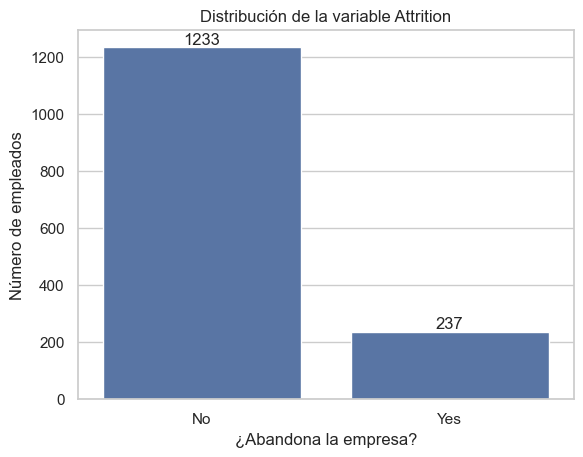

In [56]:
conteo = df['Attrition'].value_counts()
porcentaje = df['Attrition'].value_counts(normalize=True).mul(100).round(1)
display(pd.DataFrame({'n': conteo, '%': porcentaje}))

ax = sns.countplot(data=df, x='Attrition', order=['No', 'Yes'])
ax.bar_label(ax.containers[0])
ax.set_title('Distribución de la variable Attrition')
ax.set_xlabel('¿Abandona la empresa?')
ax.set_ylabel('Número de empleados')
plt.savefig(FIG_DIR / '01_attrition.png', dpi=150, bbox_inches='tight')
plt.show()

**Resultado:** 1.233 empleados (83,9 %) permanecen en la empresa y 237 (16,1 %) la abandonan, es decir, aproximadamente una baja por cada cinco empleados que se quedan. Las clases están **desbalanceadas**, lo que tiene tres consecuencias para el resto del trabajo:

1. **La accuracy no sirve como métrica.** Un modelo que prediga siempre "No" acertaría el 83,9 % de las veces sin detectar ninguna baja. Este valor se toma como *baseline*: el modelo solo es útil si detecta bajas, no si acierta mucho.
2. **La evaluación se centrará en la clase minoritaria**: el *recall* (porcentaje de bajas reales que el modelo detecta), la precisión (porcentaje de alarmas que son bajas reales) y el área bajo la curva ROC.
3. **La partición en entrenamiento y test será estratificada**, para que ambos conjuntos mantengan la proporción 84/16. Con solo 237 bajas, una partición aleatoria sin estratificar podría dejar el test con demasiadas o muy pocas.

El desbalanceo se tratará ajustando el umbral de decisión del modelo, no reponderando las clases durante el entrenamiento, para que las probabilidades estimadas sigan reflejando la proporción real de bajas. Esta decisión se justifica en el apartado de modelado.

### 1.5. Variables numéricas según Attrition

Se compara la distribución de cada variable numérica entre los empleados que abandonan la empresa y los que permanecen. Para cada variable se calculan la mediana y la media de cada grupo y la asimetría de la distribución, y se aplica la prueba de Mann-Whitney para contrastar si las diferencias entre grupos son estadísticamente significativas (p < 0,05). Se utiliza esta prueba no paramétrica porque no requiere normalidad y varias variables presentan una fuerte asimetría.

In [57]:
from scipy.stats import mannwhitneyu

numericas = ['Age', 'DailyRate', 'DistanceFromHome', 'HourlyRate', 'MonthlyIncome',
             'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'TotalWorkingYears',
             'TrainingTimesLastYear', 'YearsAtCompany', 'YearsInCurrentRole',
             'YearsSinceLastPromotion', 'YearsWithCurrManager']

se_va = df['Attrition'] == 'Yes'

filas = []
for col in numericas:
    p = mannwhitneyu(df.loc[se_va, col], df.loc[~se_va, col]).pvalue
    filas.append({
        'variable': col,
        'mediana_No': df.loc[~se_va, col].median(),
        'mediana_Yes': df.loc[se_va, col].median(),
        'media_No': round(df.loc[~se_va, col].mean(), 1),
        'media_Yes': round(df.loc[se_va, col].mean(), 1),
        'asimetria': round(df[col].skew(), 2),
        'p_valor': round(p, 4),
    })

tabla_num = pd.DataFrame(filas).set_index('variable').sort_values('p_valor')
tabla_num

,mediana_No,mediana_Yes,media_No,media_Yes,asimetria,p_valor
variable,,,,,,
Age,36.0,32.0,37.6,33.6,0.41,0.0000
MonthlyIncome,5204.0,3202.0,6832.7,4787.1,1.37,0.0000
YearsAtCompany,6.0,3.0,7.4,5.1,1.76,0.0000
TotalWorkingYears,10.0,7.0,11.9,8.2,1.12,0.0000
YearsWithCurrManager,3.0,2.0,4.4,2.9,0.83,0.0000
YearsInCurrentRole,3.0,2.0,4.5,2.9,0.92,0.0000
DistanceFromHome,7.0,9.0,8.9,10.6,0.96,0.0024
DailyRate,817.0,699.0,812.5,750.4,-0.00,0.0290
YearsSinceLastPromotion,1.0,1.0,2.2,1.9,1.98,0.0412


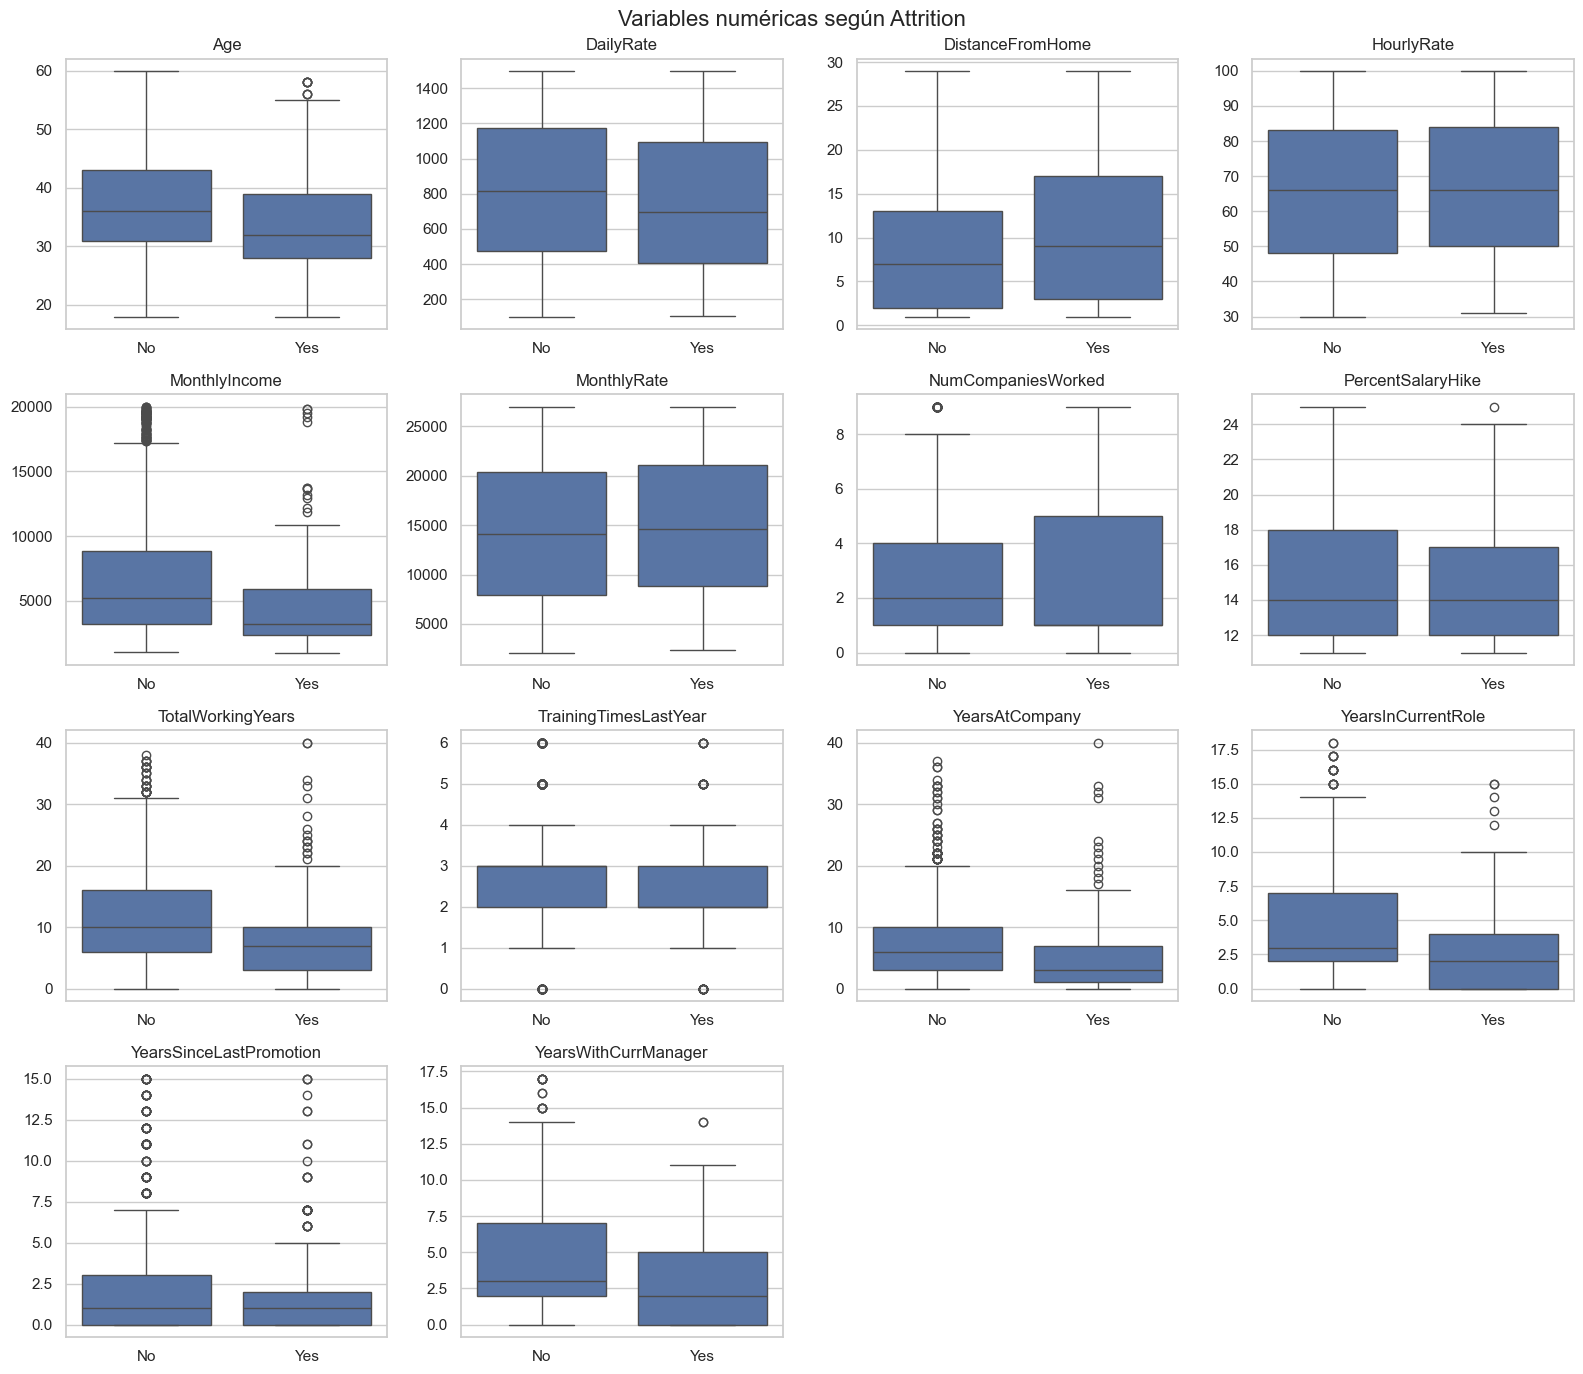

In [58]:
fig, axes = plt.subplots(4, 4, figsize=(16, 14))

for ax, col in zip(axes.flat, numericas):
    sns.boxplot(data=df, x='Attrition', y=col, order=['No', 'Yes'], ax=ax)
    ax.set_title(col)
    ax.set_xlabel('')
    ax.set_ylabel('')

# Oculta los 2 huecos sobrantes de la cuadrícula (16 huecos, 14 variables)
for ax in axes.flat[len(numericas):]:
    ax.set_visible(False)

fig.suptitle('Variables numéricas según Attrition', fontsize=16)
plt.tight_layout()
plt.savefig(FIG_DIR / '02_numericas_boxplot.png', dpi=150, bbox_inches='tight')
plt.show()

**Resultado:**

**Diferencias claras (p < 0,001).** Los empleados que abandonan la empresa son, en general, **más jóvenes, cobran menos y llevan menos tiempo** en la empresa, en su puesto y con su responsable:
- Edad mediana de 32 años frente a 36.
- Salario mensual mediano de 3.202 frente a 5.204, alrededor de un 38 % menos.
- Mediana de 3 años en la empresa frente a 6, y de 7 años de experiencia total frente a 10.
- Menos años en el puesto actual y con el responsable actual (mediana de 2 frente a 3 en ambos casos).

Estas seis variables describen en el fondo lo mismo: **la etapa de la carrera profesional**. Es esperable que estén muy correlacionadas entre sí (a más edad, más experiencia, más antigüedad y más salario), lo que se comprobará en el análisis de colinealidad. El modelo multivariante permitirá separar qué parte del efecto corresponde a cada una.

**Diferencias moderadas.** `DistanceFromHome` también es significativa (p = 0,002): quienes se van viven algo más lejos (mediana de 9 frente a 7).

**Diferencias débiles o nulas.** `DailyRate`, `YearsSinceLastPromotion` y `TrainingTimesLastYear` presentan p-valores cercanos a 0,05. Al realizarse 14 contrastes a la vez, aumenta la probabilidad de obtener algún resultado significativo por azar. Aplicando la corrección de Bonferroni (umbral 0,05 / 14 ≈ 0,0036), estas tres variables dejan de ser significativas, mientras que las siete anteriores se mantienen. `NumCompaniesWorked`, `PercentSalaryHike`, `MonthlyRate` y `HourlyRate` no muestran diferencias.

**Dos observaciones relevantes para el preprocesado:**
1. **`YearsSinceLastPromotion` es ligeramente menor en quienes se van** (media de 1,9 frente a 2,2), lo contrario de lo que cabría esperar si la falta de ascensos impulsara la salida. La explicación más probable es que quienes se van llevan menos tiempo en la empresa y, por tanto, han tenido menos tiempo para acumular años sin ascender. Esto refuerza la idea de medir el estancamiento **en relación con la antigüedad** (años sin ascenso / años en la empresa) en lugar de en valor absoluto.
2. **Las tarifas no reflejan diferencias consistentes.** `HourlyRate` y `MonthlyRate` no se relacionan con la baja, y `DailyRate` solo de forma débil y no robusta a la corrección por comparaciones múltiples. Junto con su falta de relación con el salario, que se comprobará en el análisis de correlaciones, esto apoya su eliminación.

**Asimetría y valores atípicos.** `MonthlyIncome`, `TotalWorkingYears` y las variables de años en la empresa presentan una asimetría positiva marcada (entre 1,1 y 2,0): la mayoría de los empleados tiene valores bajos y unos pocos, muy altos. Los puntos aislados de los diagramas de caja corresponden a empleados con mucha antigüedad o salarios altos, que son valores plausibles y no errores, por lo que se mantienen. En el preprocesado se valorará aplicar una transformación logarítmica a las variables más asimétricas.

### 1.6. Variables categóricas y ordinales según Attrition

Se calcula la tasa de bajas (porcentaje de empleados que abandonan la empresa) en cada categoría de las variables categóricas y ordinales, y se compara con la tasa global del 16,1 %. Para cada variable se aplica la prueba chi-cuadrado de independencia, que contrasta si la tasa de bajas varía entre categorías, y se calcula la V de Cramér, que mide la intensidad de la relación entre 0 (ninguna) y 1 (total). Las variables sensibles (`Gender` y `MaritalStatus`) se analizan por separado en el apartado 1.7.

In [59]:
from scipy.stats import chi2_contingency

categoricas = ['OverTime', 'BusinessTravel', 'Department', 'JobRole', 'JobLevel',
               'StockOptionLevel', 'EducationField', 'Education',
               'EnvironmentSatisfaction', 'JobSatisfaction', 'RelationshipSatisfaction',
               'WorkLifeBalance', 'JobInvolvement', 'PerformanceRating']

# 1 si el empleado se va, 0 si se queda: su media por grupo es la tasa de bajas
baja = (df['Attrition'] == 'Yes').astype(int)

filas = []
for col in categoricas:
    tabla = pd.crosstab(df[col], df['Attrition'])
    chi2, p, _, _ = chi2_contingency(tabla)
    v_cramer = np.sqrt(chi2 / (tabla.values.sum() * (min(tabla.shape) - 1)))
    tasa = baja.groupby(df[col]).mean() * 100
    filas.append({
        'variable': col,
        'categorias': df[col].nunique(),
        'categoria_min': tasa.idxmin(),
        'tasa_min_%': round(tasa.min(), 1),
        'categoria_max': tasa.idxmax(),
        'tasa_max_%': round(tasa.max(), 1),
        'v_cramer': round(v_cramer, 3),
        'p_valor': round(p, 4),
    })

tabla_cat = pd.DataFrame(filas).set_index('variable').sort_values('v_cramer', ascending=False)
tabla_cat

,categorias,categoria_min,tasa_min_%,categoria_max,tasa_max_%,v_cramer,p_valor
variable,,,,,,,
OverTime,2,No,10.4,Yes,30.5,0.244,0.0000
JobRole,9,Research Director,2.5,Sales Representative,39.8,0.242,0.0000
JobLevel,5,4,4.7,1,26.3,0.222,0.0000
StockOptionLevel,4,2,7.6,0,24.4,0.203,0.0000
JobInvolvement,4,4,9.0,1,33.7,0.139,0.0000
BusinessTravel,3,Non-Travel,8.0,Travel_Frequently,24.9,0.128,0.0000
EnvironmentSatisfaction,4,4,13.5,1,25.4,0.124,0.0001
JobSatisfaction,4,4,11.3,1,22.8,0.109,0.0006
WorkLifeBalance,4,3,14.2,1,31.2,0.105,0.0010


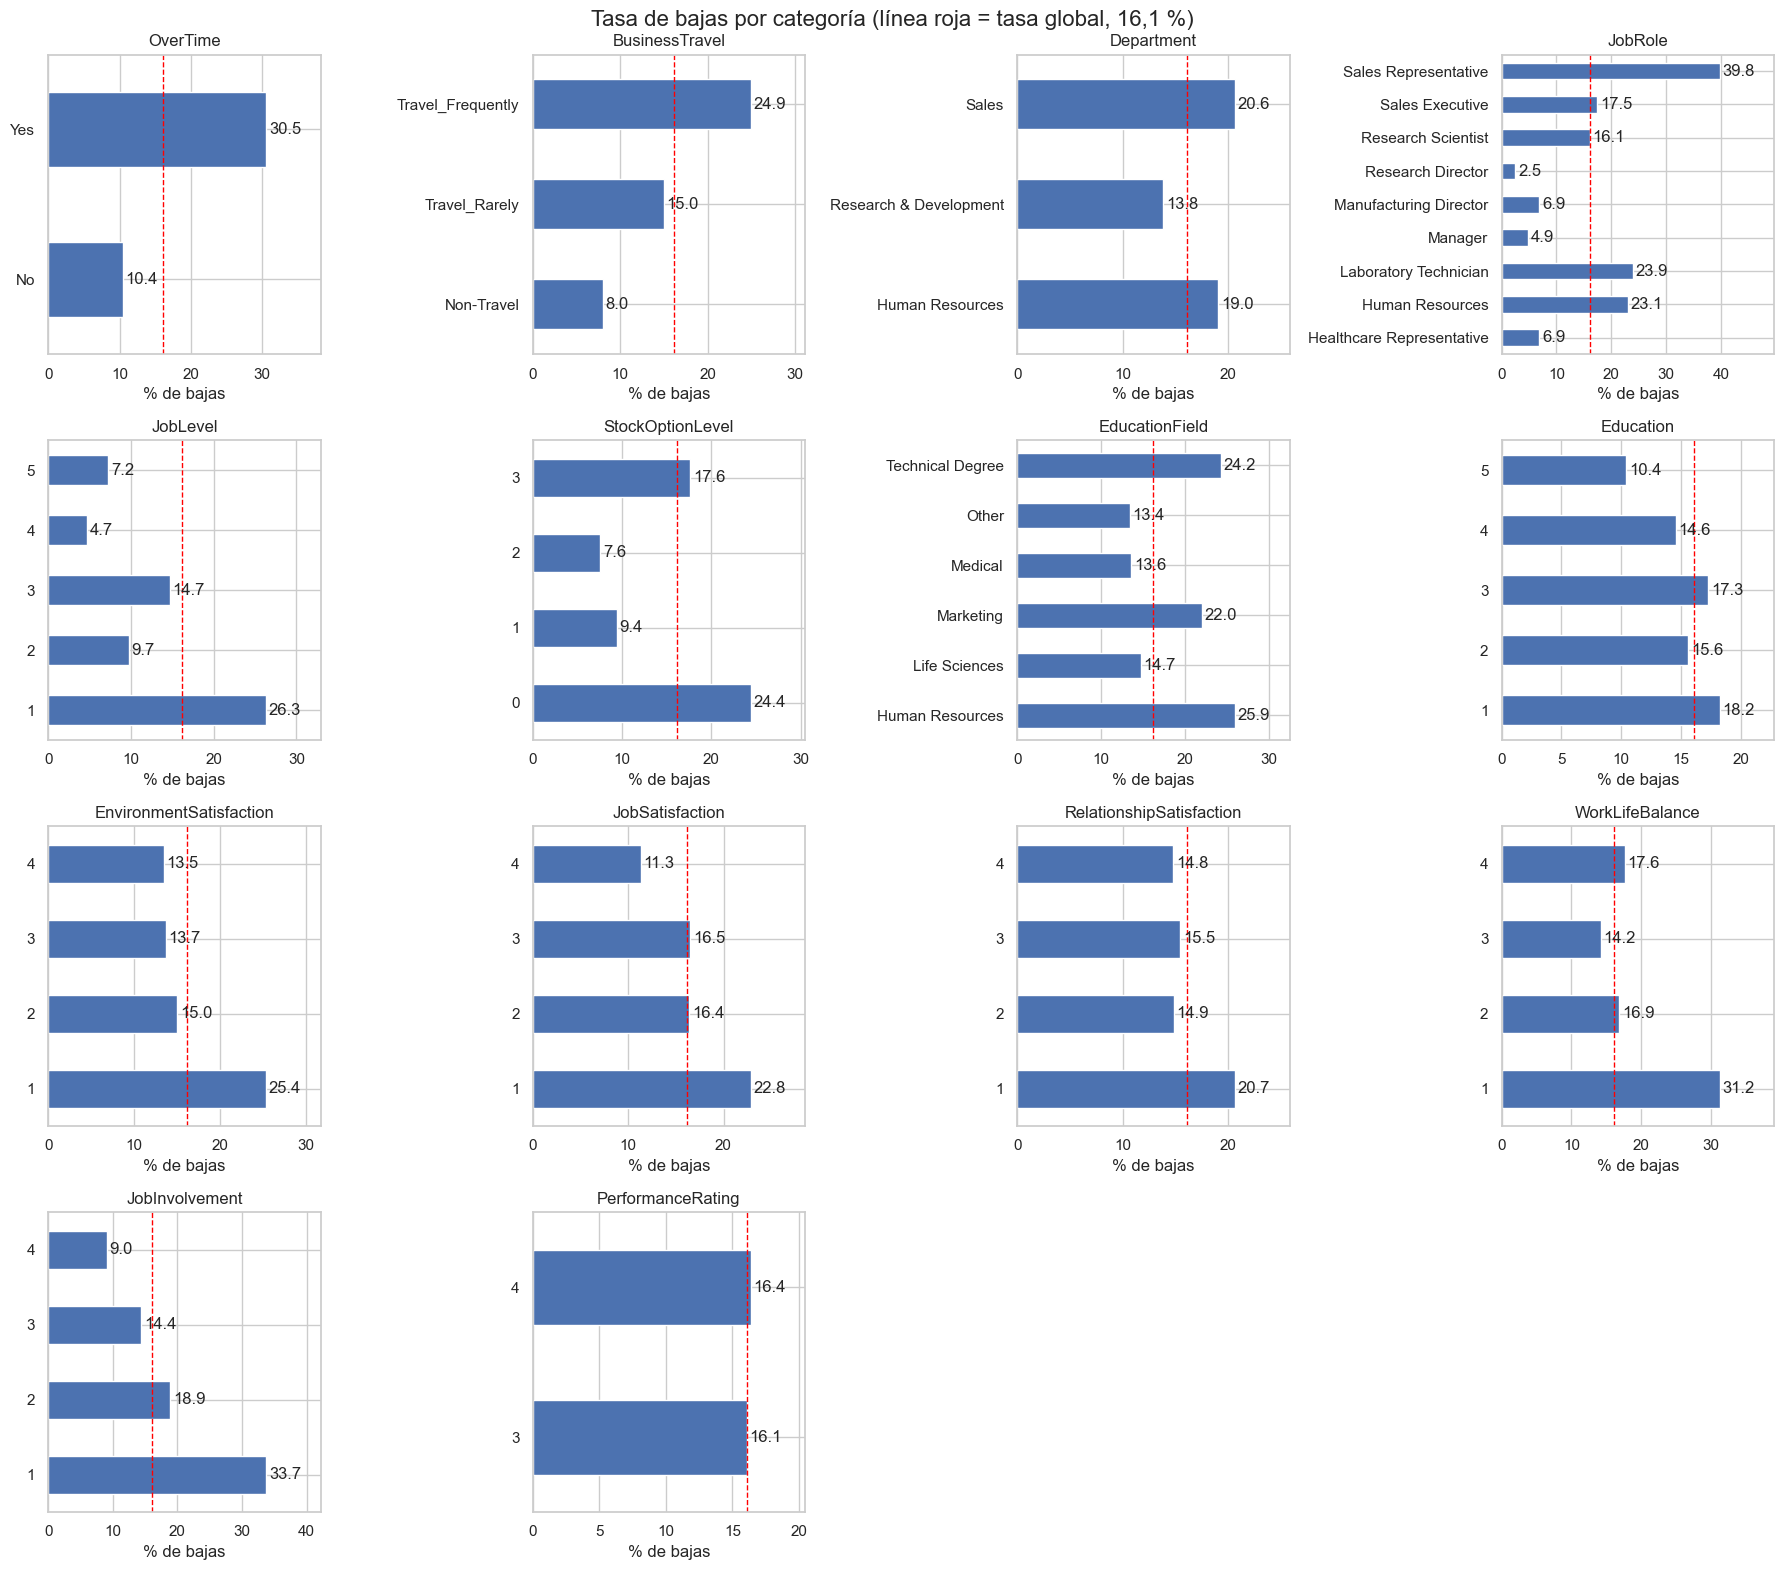

In [60]:
orden_viajes = ['Non-Travel', 'Travel_Rarely', 'Travel_Frequently']
tasa_global = baja.mean() * 100

fig, axes = plt.subplots(4, 4, figsize=(18, 16))

for ax, col in zip(axes.flat, categoricas):
    tasa = baja.groupby(df[col]).mean() * 100
    if col == 'BusinessTravel':
        tasa = tasa.reindex(orden_viajes)
    tasa.plot.barh(ax=ax)
    ax.axvline(tasa_global, color='red', linestyle='--', linewidth=1)
    ax.bar_label(ax.containers[0], fmt='%.1f', padding=2)
    ax.set_xlim(0, tasa.max() * 1.25)
    ax.set_title(col)
    ax.set_xlabel('% de bajas')
    ax.set_ylabel('')

# Oculta los 2 huecos sobrantes de la cuadrícula
for ax in axes.flat[len(categoricas):]:
    ax.set_visible(False)

fig.suptitle('Tasa de bajas por categoría (línea roja = tasa global, 16,1 %)', fontsize=16)
plt.tight_layout()
plt.savefig(FIG_DIR / '03_categoricas_tasa_bajas.png', dpi=150, bbox_inches='tight')
plt.show()

**Resultado:**

**Relación más fuerte (V de Cramér ≥ 0,20):**
- **`OverTime`** es la variable categórica más asociada a la baja: quienes hacen horas extra se van en un 30,5 % de los casos, frente al 10,4 % de quienes no las hacen, casi el triple.
- **`JobRole`**: los *Sales Representatives* presentan una tasa del 39,8 %, más del doble de la media, seguidos de *Laboratory Technician* (23,9 %) y *Human Resources* (23,1 %). En los puestos directivos (*Research Director*, *Manager*, *Manufacturing Director*) la tasa no llega al 7 %.
- **`JobLevel`**: el nivel 1 concentra la rotación (26,3 %), mientras que en los demás niveles se mantiene por debajo de la media.
- **`StockOptionLevel`**: los empleados sin opciones sobre acciones (nivel 0) se van en un 24,4 % de los casos, frente a menos del 10 % en los niveles 1 y 2.

**Relación moderada o débil (V entre 0,10 y 0,14):** `JobInvolvement`, `BusinessTravel`, `EnvironmentSatisfaction`, `JobSatisfaction` y `WorkLifeBalance`. En `BusinessTravel` la relación es creciente y ordenada (8,0 % → 15,0 % → 24,9 % según aumenta la frecuencia de viajes), y en `JobInvolvement` decreciente (del 33,7 % con implicación baja al 9,0 % con implicación muy alta).

**Sin relación robusta:** `EducationField` y `Department` son significativas al 5 %, pero no superan la corrección de Bonferroni (umbral 0,05 / 14 ≈ 0,0036) y su intensidad es baja. `RelationshipSatisfaction`, `Education` y `PerformanceRating` no muestran relación con la baja. En el caso de `PerformanceRating`, la tasa es prácticamente idéntica en sus dos valores (16,1 % y 16,4 %), lo que confirma que no aporta información y que el dataset no permite distinguir la rotación de los empleados mejor valorados.

**Observaciones para el preprocesado:**
1. **Varias variables ordinales no tienen un efecto lineal.** En las satisfacciones y en `WorkLifeBalance`, el aumento de la rotación se concentra en el nivel más bajo (1), mientras que los niveles 2 a 4 se mantienen cerca de la media. Algo parecido ocurre en `JobLevel` (el salto está entre el nivel 1 y el resto) y en `StockOptionLevel`, cuyo nivel 3 vuelve a superar la media. Tratarlas como numéricas supone que cada escalón tiene el mismo efecto, lo que aquí no se cumple del todo. Esto apoya construir el índice de satisfacción como **recuento de dimensiones en nivel 1** en lugar de como media, y se valorará cómo codificar `StockOptionLevel` y `JobLevel`.
2. **`Department` y `JobRole` son redundantes**: cada puesto pertenece, en su mayoría, a un solo departamento, y `JobRole` aporta más detalle (V de 0,242 frente a 0,086). Incluir ambas generaría colinealidad entre sus variables *dummy*.
3. **`JobLevel`, `JobRole` y las variables numéricas de la sección 1.5 describen de nuevo la etapa de la carrera**: el nivel 1 y los puestos de entrada concentran a los empleados más jóvenes y con menor salario. La colinealidad entre todas ellas se analizará en el apartado de correlaciones.
4. Algunas categorías son pequeñas (por ejemplo, `Human Resources` en `EducationField`, con 27 empleados), por lo que sus tasas son menos fiables.

### 1.7. Variables sensibles: sexo, estado civil y edad

`Gender`, `MaritalStatus` y `Age` son características personales del empleado y no condiciones de trabajo sobre las que la empresa pueda actuar. Su uso en un modelo que apoye decisiones sobre personas plantea riesgos de discriminación; además, los sistemas de IA aplicados a la gestión de trabajadores se consideran de alto riesgo en la normativa europea. Por ello se analizan por separado: se calcula la tasa de bajas en cada categoría (la edad se agrupa en tramos) y se comprueba si alguna otra variable del dataset actúa como *proxy*, es decir, si está tan ligada a una variable sensible que permitiría al modelo deducirla aunque esta se elimine.

In [61]:
df_sens = df[['Gender', 'MaritalStatus']].copy()
df_sens['TramoEdad'] = pd.cut(df['Age'], bins=[17, 24, 29, 34, 39, 44, 49, 60],
                              labels=['18-24', '25-29', '30-34', '35-39', '40-44', '45-49', '50-60'])

for col in df_sens.columns:
    tabla = pd.crosstab(df_sens[col], df['Attrition'])
    chi2, p, _, _ = chi2_contingency(tabla)
    v = np.sqrt(chi2 / (tabla.values.sum() * (min(tabla.shape) - 1)))
    resumen_sens = pd.DataFrame({
        'n': df_sens[col].value_counts(sort=False),
        'tasa_bajas_%': (baja.groupby(df_sens[col], observed=True).mean() * 100).round(1),
    })
    print(f'\n{col}  |  V de Cramér = {v:.3f}  |  p-valor = {p:.4f}')
    display(resumen_sens)

print('\nNúmero de empleados por estado civil y nivel de stock options:')
display(pd.crosstab(df['MaritalStatus'], df['StockOptionLevel']))


Gender  |  V de Cramér = 0.028  |  p-valor = 0.2906


,n,tasa_bajas_%
Gender,,
Female,588,14.8
Male,882,17.0



MaritalStatus  |  V de Cramér = 0.177  |  p-valor = 0.0000


,n,tasa_bajas_%
MaritalStatus,,
Divorced,327,10.1
Married,673,12.5
Single,470,25.5



TramoEdad  |  V de Cramér = 0.213  |  p-valor = 0.0000


,n,tasa_bajas_%
TramoEdad,,
18-24,97,39.2
25-29,229,23.1
30-34,325,18.2
35-39,297,10.1
40-44,208,10.1
45-49,141,9.2
50-60,173,13.3



Número de empleados por estado civil y nivel de stock options:


StockOptionLevel,0,1,2,3
MaritalStatus,,,,
Divorced,8,195,75,49
Married,153,401,83,36
Single,470,0,0,0


In [62]:
print('Tasa de bajas (%) por estado civil y nivel de stock options:')
display(pd.crosstab(df['MaritalStatus'], df['StockOptionLevel'],
                    values=baja, aggfunc='mean').mul(100).round(1))

Tasa de bajas (%) por estado civil y nivel de stock options:


StockOptionLevel,0,1,2,3
MaritalStatus,,,,
Divorced,37.5,9.2,6.7,14.3
Married,20.3,9.5,8.4,22.2
Single,25.5,NaN,NaN,NaN


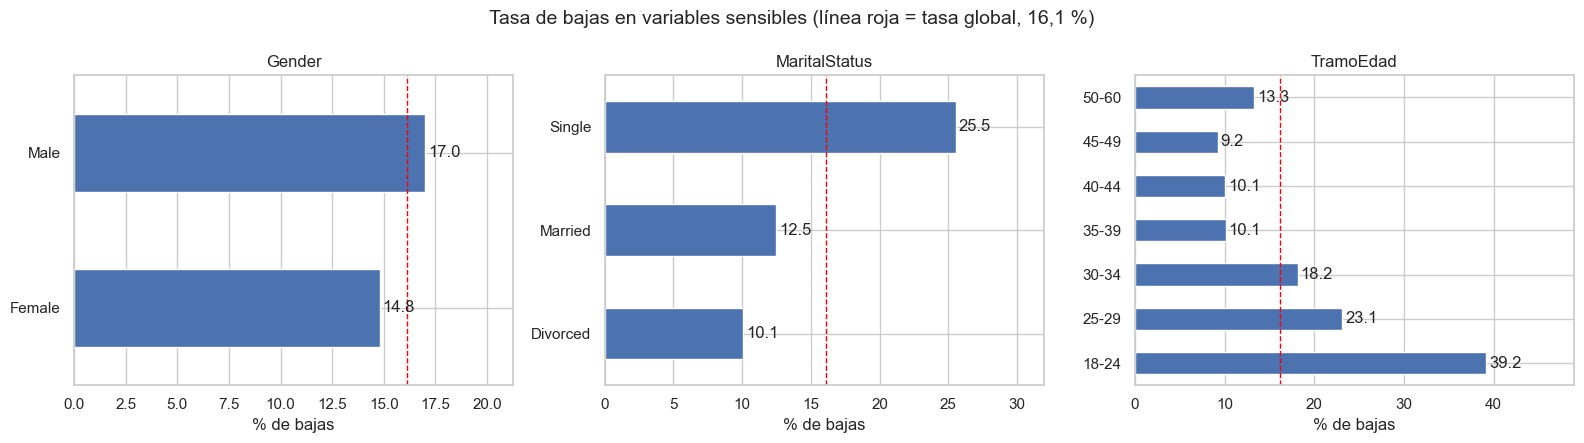

In [63]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, col in zip(axes, df_sens.columns):
    tasa = baja.groupby(df_sens[col], observed=True).mean() * 100
    tasa.plot.barh(ax=ax)
    ax.axvline(tasa_global, color='red', linestyle='--', linewidth=1)
    ax.bar_label(ax.containers[0], fmt='%.1f', padding=2)
    ax.set_xlim(0, tasa.max() * 1.25)
    ax.set_title(col)
    ax.set_xlabel('% de bajas')
    ax.set_ylabel('')

fig.suptitle('Tasa de bajas en variables sensibles (línea roja = tasa global, 16,1 %)', fontsize=14)
plt.tight_layout()
plt.savefig(FIG_DIR / '04_variables_sensibles.png', dpi=150, bbox_inches='tight')
plt.show()

**Resultado:**

- **`Gender` no se relaciona con la baja** (14,8 % en mujeres frente a 17,0 % en hombres; p = 0,29). Excluirla del modelo no supone pérdida de información.
- **`MaritalStatus` sí se relaciona**: los empleados solteros se van en un 25,5 % de los casos, frente al 12,5 % de los casados y el 10,1 % de los divorciados (V de Cramér = 0,18).
- **La edad es la variable sensible con relación más intensa** (V = 0,21). La tasa de bajas desciende de forma muy marcada hasta los 35 años: 39,2 % entre 18 y 24 años, 23,1 % entre 25 y 29, y 18,2 % entre 30 y 34. A partir de ahí se estabiliza en torno al 10 %, con un ligero repunte en el tramo de 50 a 60 años (13,3 %). La relación no es lineal: el riesgo se concentra en los primeros años de la carrera profesional.

**Variables *proxy*.** El cruce entre estado civil y opciones sobre acciones muestra que **ningún empleado soltero tiene stock options**: los 470 solteros están en el nivel 0. `StockOptionLevel` actúa, por tanto, como *proxy* parcial del estado civil, ya que cualquier empleado con nivel 1 o superior es necesariamente casado o divorciado.

Sin embargo, el efecto de las stock options no se reduce al estado civil. Entre los empleados casados, quienes no tienen opciones se van en un 20,3 % de los casos, frente a menos del 10 % en los niveles 1 y 2. Por el contrario, entre los empleados sin opciones, la diferencia entre solteros (25,5 %) y casados (20,3 %) es mucho menor. Esto sugiere que buena parte de la mayor rotación de los solteros se explica por la ausencia de stock options, y probablemente también por su menor edad. Algunas combinaciones tienen muy pocos empleados (por ejemplo, divorciados sin opciones, 8 casos) y no permiten conclusiones.

De forma similar, la edad está ligada a las variables que describen la etapa de la carrera (experiencia, nivel, salario), por lo que eliminar `Age` no elimina por completo la información sobre la edad. Esta relación se cuantifica en el apartado siguiente.

**Decisión.** Que una variable personal se relacione estadísticamente con la baja no justifica su uso para tomar decisiones sobre empleados. El modelo se estimará con y sin `Gender`, `MaritalStatus` y `Age`, y si el rendimiento es similar se priorizará la versión sin ellas. `StockOptionLevel` se mantendrá, porque refleja una condición de trabajo sobre la que la empresa puede actuar y tiene un efecto propio, pero su papel como *proxy* del estado civil se tendrá en cuenta al interpretar el modelo. Dado que el efecto se concentra en no tener opciones, se codificará como variable binaria (tiene / no tiene stock options).

### 1.8. Correlaciones y colinealidad

Se analiza la relación entre las variables explicativas para detectar colinealidad, que en una regresión logística hace inestables los coeficientes y dificulta su interpretación. Se utiliza la correlación de Spearman, basada en rangos, por ser adecuada para variables ordinales y asimétricas. Para ello, `BusinessTravel` se codifica según su orden (0 = sin viajes, 1 = viajes ocasionales, 2 = viajes frecuentes) y `OverTime` como 0/1.

Además, se calcula el factor de inflación de la varianza (VIF), que mide en qué medida cada variable puede explicarse a partir del resto.El VIF se calcula como 1 / (1 − R²), donde R² es la proporción de la variable que puede explicarse a partir del resto. Un VIF de 5 indica que el 80 % de la variable es explicable por las demás, y uno de 10, el 90 %. Además, la raíz cuadrada del VIF indica cuánto se amplía el error estándar del coeficiente: con un VIF de 10, se multiplica por más de tres, lo que hace inestable su estimación e interpretación. Siguiendo la literatura, se considera que un VIF superior a 5 indica una colinealidad a vigilar y uno superior a 10, una colinealidad que debe corregirse (James et al., 2021; Kutner et al., 2005). En el contexto de la regresión logística, Menard (2002) propone el mismo criterio, expresado como tolerancia (1/VIF) inferior a 0,20 y 0,10. Estos umbrales son orientativos y no deben aplicarse de forma mecánica (O'Brien, 2007), por lo que la decisión sobre cada variable se apoya también en su significado. Este cálculo es orientativo: las variables nominales (`JobRole`, `Department`, `EducationField`, `MaritalStatus`) no se incluyen, y el VIF definitivo se calculará sobre el conjunto de entrenamiento una vez construidas las nuevas variables.

In [64]:
viajes = {'Non-Travel': 0, 'Travel_Rarely': 1, 'Travel_Frequently': 2}
ordinales = ['Education', 'EnvironmentSatisfaction', 'JobInvolvement', 'JobLevel',
             'JobSatisfaction', 'PerformanceRating', 'RelationshipSatisfaction',
             'StockOptionLevel', 'WorkLifeBalance']

df_num = df[numericas + ordinales].copy()
df_num['BusinessTravel'] = df['BusinessTravel'].map(viajes)
df_num['OverTime'] = (df['OverTime'] == 'Yes').astype(int)

corr = df_num.corr(method='spearman')

# Pares de variables con correlación fuerte (|rho| >= 0,5), sin repetir
pares = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
             .stack().rename('rho').reset_index())
pares = (pares[pares['rho'].abs() >= 0.5]
         .sort_values('rho', key=lambda s: s.abs(), ascending=False)
         .round(3))
print('Pares de variables con |rho| >= 0,5:')
display(pares)

print('\nCorrelación de las tarifas con salario, nivel y experiencia:')
display(corr.loc[['DailyRate', 'HourlyRate', 'MonthlyRate'],
                 ['MonthlyIncome', 'JobLevel', 'TotalWorkingYears']].round(3))

Pares de variables con |rho| >= 0,5:


,level_0,level_1,rho
102,MonthlyIncome,JobLevel,0.920
195,YearsAtCompany,YearsInCurrentRole,0.854
197,YearsAtCompany,YearsWithCurrManager,0.843
172,TotalWorkingYears,JobLevel,0.735
210,YearsInCurrentRole,YearsWithCurrManager,0.725
93,MonthlyIncome,TotalWorkingYears,0.710
7,Age,TotalWorkingYears,0.657
158,PercentSalaryHike,PerformanceRating,0.629
165,TotalWorkingYears,YearsAtCompany,0.594
196,YearsAtCompany,YearsSinceLastPromotion,0.520



Correlación de las tarifas con salario, nivel y experiencia:


,MonthlyIncome,JobLevel,TotalWorkingYears
DailyRate,0.016,0.004,0.021
HourlyRate,-0.020,-0.034,-0.012
MonthlyRate,0.054,0.053,0.013


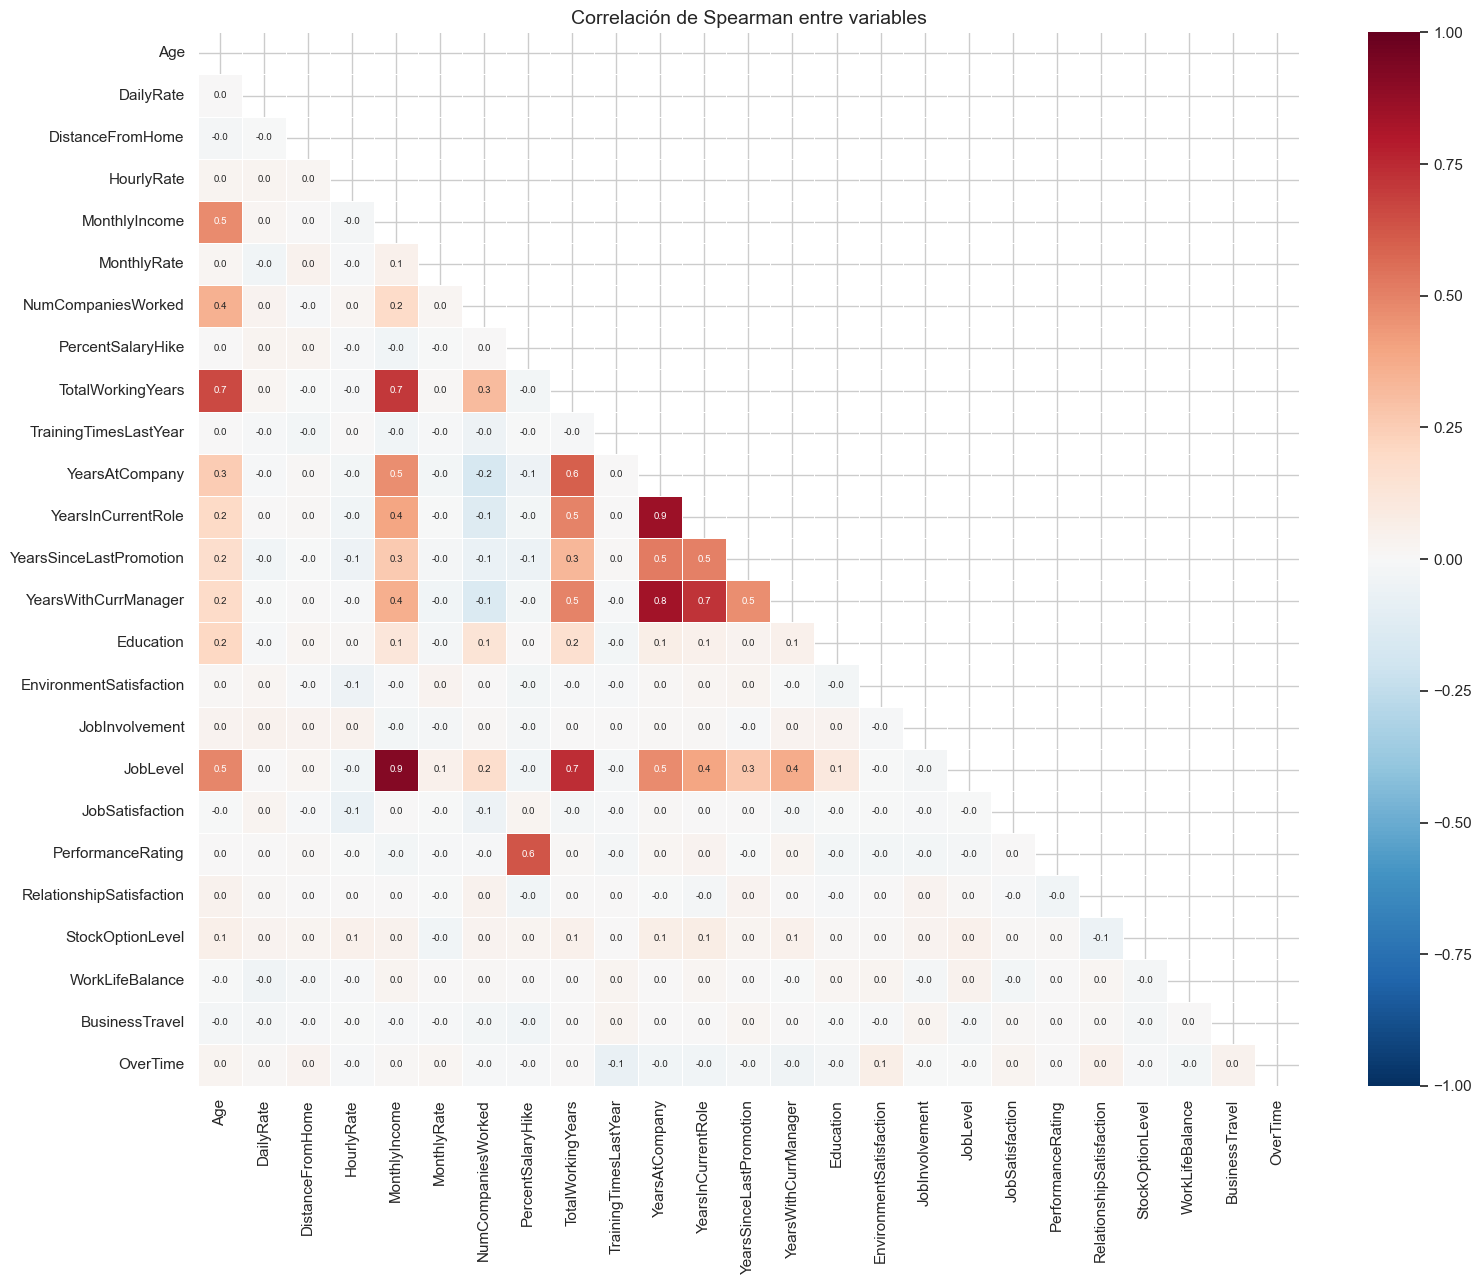

In [65]:
mascara = np.triu(np.ones(corr.shape, dtype=bool))

plt.figure(figsize=(16, 13))
sns.heatmap(corr, mask=mascara, cmap='RdBu_r', vmin=-1, vmax=1, center=0,
            annot=True, fmt='.1f', annot_kws={'size': 7}, linewidths=0.5)
plt.title('Correlación de Spearman entre variables', fontsize=14)
plt.tight_layout()
plt.savefig(FIG_DIR / '05_correlaciones.png', dpi=150, bbox_inches='tight')
plt.show()

In [66]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

# Se excluyen las tarifas, cuya eliminación ya está prevista
candidatas = [c for c in df_num.columns if c not in ['DailyRate', 'HourlyRate', 'MonthlyRate']]
X_vif = add_constant(df_num[candidatas])

vif = pd.Series(
    [variance_inflation_factor(X_vif.values, i) for i in range(1, X_vif.shape[1])],
    index=candidatas, name='VIF'
).round(2).sort_values(ascending=False)
vif

JobLevel                    11.18
MonthlyIncome               10.79
TotalWorkingYears            4.77
YearsAtCompany               4.57
YearsWithCurrManager         2.78
YearsInCurrentRole           2.71
PercentSalaryHike            2.52
PerformanceRating            2.51
Age                          2.04
YearsSinceLastPromotion      1.67
NumCompaniesWorked           1.26
Education                    1.06
RelationshipSatisfaction     1.02
TrainingTimesLastYear        1.02
OverTime                     1.02
DistanceFromHome             1.01
JobInvolvement               1.01
EnvironmentSatisfaction      1.01
JobSatisfaction              1.01
StockOptionLevel             1.01
WorkLifeBalance              1.01
BusinessTravel               1.01
Name: VIF, dtype: float64

**Resultado:**

El mapa de calor muestra que la mayoría de las variables apenas se relacionan entre sí. La colinealidad se concentra en **dos bloques**:

1. **Etapa de la carrera profesional.** `MonthlyIncome` y `JobLevel` presentan la correlación más alta del conjunto (ρ = 0,92): en la práctica, el salario está determinado por el nivel jerárquico. Ambas se relacionan a su vez con `TotalWorkingYears` (0,74 y 0,71), y esta con `Age` (0,66). Esto confirma lo observado en los apartados anteriores: edad, experiencia, nivel y salario describen un mismo fenómeno.
2. **Antigüedad en la empresa.** `YearsAtCompany` está muy correlacionada con `YearsInCurrentRole` (0,85) y con `YearsWithCurrManager` (0,84), y estas dos entre sí (0,73). Las tres variables miden casi lo mismo: en este dataset, permanecer en la empresa suele implicar seguir en el mismo puesto y con el mismo responsable. `YearsSinceLastPromotion` se relaciona de forma moderada con ellas (en torno a 0,5).

**Otras relaciones relevantes:**
- `PercentSalaryHike` y `PerformanceRating` se correlacionan (0,63): los empleados con mejor evaluación reciben subidas mayores. Ninguna de las dos se relacionaba con la baja (apartados 1.5 y 1.6).
- La correlación entre `Age` y `TotalWorkingYears` (0,66) confirma que **eliminar la edad no elimina toda la información sobre ella**: la experiencia total actúa como *proxy* parcial de la edad.

**Las tarifas no miden el salario.** `DailyRate`, `HourlyRate` y `MonthlyRate` tienen correlaciones prácticamente nulas (|ρ| ≤ 0,05) con el salario, el nivel y la experiencia. Unido a que no se relacionan de forma robusta con la baja (apartado 1.5), su significado no puede identificarse, por lo que **se eliminan del análisis**, tal como permite el enunciado.

**Las variables de satisfacción son independientes entre sí.** Las cuatro escalas de satisfacción, la implicación, la conciliación, las horas extra y los viajes no se correlacionan con ninguna otra variable (ρ ≈ 0). No presentan problemas de colinealidad y cada una aporta información distinta. Esto tiene una implicación para el índice de satisfacción previsto: al tratarse de dimensiones no relacionadas, promediarlas mezclaría aspectos diferentes. Se refuerza la opción de construirlo como recuento de dimensiones en nivel bajo, y se comparará con mantener las escalas por separado.

**Factor de inflación de la varianza (VIF).** Solo dos variables superan el umbral de 10: `JobLevel` (11,2) y `MonthlyIncome` (10,8). Su colinealidad debe corregirse antes del modelado. Para ello se mantendrá `JobLevel` y se sustituirá `MonthlyIncome` por el **salario relativo**: el salario de cada empleado dividido entre la mediana salarial de su nivel. Así se conserva la información de si un empleado cobra más o menos que sus compañeros de nivel sin duplicar la información del propio nivel.

`TotalWorkingYears` (4,8) y `YearsAtCompany` (4,6) quedan cerca del umbral de 5, por lo que se vigilarán; previsiblemente bajarán al eliminar `MonthlyIncome`, con la que están relacionadas. Las variables del bloque de antigüedad (`YearsInCurrentRole` y `YearsWithCurrManager`, en torno a 2,7) no alcanzan el umbral de atención pese a su alta correlación por pares: conservan suficiente información propia, por lo que no se eliminan en esta fase. El resto de variables presenta valores cercanos a 1, sin colinealidad.

El VIF se basa en relaciones lineales sobre los valores originales y considera cada variable frente a todas las demás a la vez, por lo que no coincide exactamente con las correlaciones de Spearman por pares. Se recalculará sobre el conjunto de entrenamiento una vez construidas las nuevas variables, ya que los ratios previstos (como el estancamiento, que utiliza `YearsAtCompany`) pueden introducir colinealidad nueva.

### 1.9. Coherencia de NumCompaniesWorked

Antes de construir la tasa de cambio de empresa (empresas anteriores / años de experiencia), se comprueba la coherencia de `NumCompaniesWorked`. La documentación del dataset no aclara si la variable cuenta solo las empresas anteriores o incluye la actual. Para contrastarlo, se identifica qué empleados tienen experiencia previa a la empresa actual (`TotalWorkingYears` mayor que `YearsAtCompany`) y se cruza con el número de empresas declarado. También se verifica que ningún empleado tenga más años en la empresa que años de experiencia total, lo que sería imposible.

In [67]:
imposibles = (df['YearsAtCompany'] > df['TotalWorkingYears']).sum()
print('Empleados con más años en la empresa que de experiencia total:', imposibles)

experiencia_previa = (df['TotalWorkingYears'] > df['YearsAtCompany']).map(
    {True: 'Con experiencia previa', False: 'Sin experiencia previa'})

print('\nNúmero de empleados según empresas declaradas y experiencia previa:')
pd.crosstab(df['NumCompaniesWorked'], experiencia_previa)

Empleados con más años en la empresa que de experiencia total: 0

Número de empleados según empresas declaradas y experiencia previa:


col_0,Con experiencia previa,Sin experiencia previa
NumCompaniesWorked,,
0,197,0
1,47,474
2,146,0
3,159,0
4,139,0
5,63,0
6,70,0
7,74,0
8,49,0


**Resultado:** no hay registros imposibles (ningún empleado tiene más años en la empresa que de experiencia total). Sin embargo, `NumCompaniesWorked` no es coherente con ninguna interpretación:
- Si contara solo las empresas anteriores, los 474 empleados sin experiencia previa deberían tener 0, y figuran con 1.
- Si incluyera la empresa actual, el valor 0 no debería existir; sin embargo, 197 empleados lo tienen, y todos ellos cuentan con experiencia previa. Además, 47 empleados con experiencia previa figuran con una sola empresa.

La segunda interpretación es la más plausible (coherente para el 83,4 % de los empleados), pero 244 registros (16,6 %) no encajan y no es posible determinar su significado real.

**Decisión:** se descarta construir la tasa de cambio de empresa (empresas / años de experiencia), ya que dividir un valor poco fiable entre la experiencia amplificaría el error; por ejemplo, un empleado con amplia experiencia previa registrado con 0 empresas aparecería como el perfil menos cambiante. `NumCompaniesWorked` se mantiene en su forma original como variable candidata, y su incoherencia se señala como limitación del dataset.

### 1.10. Conclusiones del análisis exploratorio

**Calidad de los datos.** El conjunto no contiene valores nulos, duplicados ni registros imposibles. Se identifican siete variables sin valor para el análisis: tres constantes (`EmployeeCount`, `Over18`, `StandardHours`), un identificador (`EmployeeNumber`) y tres tarifas (`DailyRate`, `HourlyRate`, `MonthlyRate`) cuyo significado no puede identificarse, al no guardar relación con el salario, el nivel ni la experiencia.

**Variable objetivo.** El 16,1 % de los empleados abandona la empresa. Este desbalanceo obliga a utilizar una partición estratificada y a evaluar el modelo con *recall*, precisión y área bajo la curva ROC en lugar de con la accuracy, cuyo valor de referencia (predecir siempre "No") ya es del 83,9 %.

**Perfil asociado a la baja.** Analizadas de una en una, las variables muestran que la rotación se concentra en:
- **Empleados al inicio de su carrera**: más jóvenes, en el nivel 1, con menor salario, menos experiencia y menos antigüedad.
- **Condiciones de trabajo exigentes**: horas extra (30,5 % de bajas frente a 10,4 %) y viajes frecuentes.
- **Determinados puestos**, especialmente *Sales Representative* (39,8 %).
- **Ausencia de stock options**, con un efecto propio aunque ligado en parte al estado civil.
- **Nivel más bajo de implicación, satisfacción con el entorno y el puesto, y conciliación.**

No se relacionan con la baja el sexo, el nivel educativo, la satisfacción con las relaciones, la evaluación de desempeño ni la subida salarial. Todas las asociaciones individuales son pequeñas, lo que justifica un modelo multivariante que combine los distintos factores.

**Decisiones para el preprocesado:**
1. **Eliminar** las siete variables sin valor analítico y `Department`, redundante con `JobRole`.
2. **Sustituir `MonthlyIncome` por el salario relativo a la mediana de su nivel**, para corregir su colinealidad con `JobLevel` (VIF superior a 10).
3. **Construir dos nuevas variables**: un indicador de insatisfacción (número de dimensiones de satisfacción y conciliación en el nivel más bajo), que se comparará con mantener las escalas por separado, y un ratio de estancamiento (años sin ascenso respecto a la antigüedad). Se descarta la tasa de cambio de empresa por la incoherencia de `NumCompaniesWorked`.
4. **Codificar** `StockOptionLevel` como binaria (tiene / no tiene), `OverTime` y `Gender` como 0/1, `BusinessTravel` según su orden, las escalas ordinales como numéricas y las nominales (`JobRole`, `EducationField`, `MaritalStatus`) mediante variables *dummy*.
5. **Valorar** una transformación logarítmica para las variables más asimétricas y una codificación alternativa para las ordinales con efecto no lineal, como `JobLevel`.
6. **Estimar el modelo con y sin las variables sensibles** (`Gender`, `MaritalStatus` y `Age`), teniendo en cuenta que `StockOptionLevel` y `TotalWorkingYears` actúan como *proxies* parciales del estado civil y la edad.
7. **Recalcular el VIF** sobre el conjunto de entrenamiento una vez construidas las nuevas variables.

**Limitaciones detectadas.** El dataset es ficticio (creado por IBM), lo que explica patrones poco realistas como la independencia total entre las escalas de satisfacción o la ausencia de stock options en todos los solteros. `NumCompaniesWorked` presenta incoherencias en el 16,6 % de los registros, `PerformanceRating` solo toma dos valores y algunas categorías tienen muy pocos empleados.

## 2. Preprocesado

### 2.1. Partición en entrenamiento y test

Se separan los datos en un conjunto de entrenamiento (70 %) y uno de test (30 %). La partición se realiza antes de cualquier transformación que dependa de los datos, de modo que todo lo que el modelo "aprende" (medianas, escalados, umbral de decisión) se calcule únicamente con el conjunto de entrenamiento. El conjunto de test se reserva para la evaluación final y simula empleados que el modelo no ha visto, lo que evita la fuga de datos y proporciona una estimación realista del rendimiento.

La partición es estratificada para que ambos conjuntos mantengan la proporción de bajas del 16,1 %, y se fija una semilla para que el resultado sea reproducible. Antes de separar, se eliminan las variables descartadas en el análisis exploratorio, cuya lista se define en el fichero de configuración, y la variable objetivo se codifica como 1 (abandona) y 0 (permanece).

In [68]:
from sklearn.model_selection import train_test_split

target = config['data']['target']

# Variable objetivo: 1 si abandona la empresa, 0 si permanece
y = (df[target] == config['data']['positive_class']).astype(int)
X = df.drop(columns=[target] + config['preprocessing']['drop_columns'])

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=config['preprocessing']['test_size'],
    stratify=y,
    random_state=config['project']['random_state'],
)

print(f'Variables explicativas: {X.shape[1]}')
print(f'Train: {X_train.shape[0]} empleados | {y_train.sum()} bajas | tasa {y_train.mean():.1%}')
print(f'Test:  {X_test.shape[0]} empleados | {y_test.sum()} bajas | tasa {y_test.mean():.1%}')

Variables explicativas: 26
Train: 1029 empleados | 166 bajas | tasa 16.1%
Test:  441 empleados | 71 bajas | tasa 16.1%


**Resultado:** tras eliminar las variables descartadas, se dispone de 26 variables explicativas. El conjunto de entrenamiento contiene 1.029 empleados (166 bajas) y el de test 441 (71 bajas). Ambos mantienen exactamente la tasa de bajas del conjunto completo (16,1 %), lo que confirma que la estratificación ha funcionado. Con 71 bajas en el test, las métricas finales tendrán cierta variabilidad, por lo que las comparaciones entre variantes del modelo se realizarán mediante validación cruzada sobre el conjunto de entrenamiento, reservando el test para una única evaluación final.

### 2.2. Construcción de nuevas variables

A partir de las conclusiones del análisis exploratorio se construyen cuatro variables, implementadas en el módulo `src/features.py` como transformadores de scikit-learn:

- **`SalarioRelativo`**: salario mensual dividido entre la mediana salarial del nivel jerárquico del empleado. Sustituye a `MonthlyIncome` para corregir su colinealidad con `JobLevel` y recoge si el empleado cobra más o menos que sus compañeros de nivel.
- **`NumInsatisfaccion`**: número de dimensiones (satisfacción con el entorno, con el puesto, con las relaciones y conciliación) en las que el empleado se sitúa en el nivel más bajo, entre 0 y 4.
- **`Estancamiento`**: años desde el último ascenso divididos entre los años en la empresa más uno. Mide la falta de ascensos en relación con la antigüedad.
- **`TieneStockOptions`**: indicador binario que sustituye a `StockOptionLevel`, ya que el efecto sobre la baja se concentra en no tener opciones.

Cada transformador aprende los valores que necesita (por ejemplo, las medianas salariales por nivel) únicamente con el conjunto de entrenamiento y los aplica después a cualquier conjunto, lo que evita la fuga de datos. A continuación se comprueba su construcción y su relación con la baja en el conjunto de entrenamiento.

In [69]:
from sklearn.pipeline import make_pipeline
from src.features import (SalarioRelativo, IndicadorInsatisfaccion,
                          Estancamiento, TieneStockOptions)

ingenieria = make_pipeline(SalarioRelativo(), IndicadorInsatisfaccion(),
                           Estancamiento(), TieneStockOptions())
X_train_fe = ingenieria.fit_transform(X_train)

print('Mediana salarial por nivel (aprendida solo con train):')
display(ingenieria.named_steps['salariorelativo'].medianas_)

nuevas = ['SalarioRelativo', 'NumInsatisfaccion', 'Estancamiento', 'TieneStockOptions']
print('\nResumen de las nuevas variables (train):')
display(X_train_fe[nuevas].describe().round(2))

Mediana salarial por nivel (aprendida solo con train):


JobLevel
1     2660.5
2     5325.0
3     9980.0
4    16207.5
5    19179.0
Name: MonthlyIncome, dtype: float64


Resumen de las nuevas variables (train):


,SalarioRelativo,NumInsatisfaccion,Estancamiento,TieneStockOptions
count,1029.00,1029.00,1029.00,1029.00
mean,1.02,0.65,0.24,0.57
std,0.25,0.74,0.27,0.49
min,0.38,0.00,0.00,0.00
25%,0.87,0.00,0.00,0.00
50%,1.00,1.00,0.14,1.00
75%,1.13,1.00,0.43,1.00
max,1.87,3.00,0.92,1.00


In [70]:
from scipy.stats import mannwhitneyu

print('Variables continuas: mediana según baja y prueba de Mann-Whitney')
for col in ['SalarioRelativo', 'Estancamiento']:
    no, si = X_train_fe.loc[y_train == 0, col], X_train_fe.loc[y_train == 1, col]
    p = mannwhitneyu(si, no).pvalue
    print(f'  {col}: mediana No = {no.median():.2f} | mediana Yes = {si.median():.2f} | p = {p:.4f}')

print('\nTasa de bajas (%) y nº de empleados según las variables discretas:')
for col in ['NumInsatisfaccion', 'TieneStockOptions']:
    resumen_fe = pd.DataFrame({
        'n': X_train_fe[col].value_counts().sort_index(),
        'tasa_bajas_%': (y_train.groupby(X_train_fe[col]).mean() * 100).round(1),
    })
    print(f'\n{col}')
    display(resumen_fe)

Variables continuas: mediana según baja y prueba de Mann-Whitney
  SalarioRelativo: mediana No = 1.01 | mediana Yes = 0.92 | p = 0.0003
  Estancamiento: mediana No = 0.15 | mediana Yes = 0.09 | p = 0.2838

Tasa de bajas (%) y nº de empleados según las variables discretas:

NumInsatisfaccion


,n,tasa_bajas_%
NumInsatisfaccion,,
0,507,10.5
1,400,19.0
2,102,29.4
3,20,35.0



TieneStockOptions


,n,tasa_bajas_%
TieneStockOptions,,
0,440,25.0
1,589,9.5


**Resultado:**

- **Salario relativo.** Las medianas salariales por nivel, calculadas con el conjunto de entrenamiento, aumentan de forma muy marcada (de 2.661 en el nivel 1 a 19.179 en el nivel 5), lo que confirma que el salario está determinado en gran medida por el nivel. El salario relativo tiene, por construcción, una mediana de 1, y varía entre 0,38 y 1,87. Los empleados que abandonan la empresa cobran una mediana de 0,92 veces la de su nivel, frente a 1,01 en quienes permanecen (p < 0,001). Es decir, **la rotación no solo se asocia a ocupar niveles bajos, sino también a cobrar menos que los compañeros del mismo nivel**.
- **Indicador de insatisfacción.** La tasa de bajas crece de forma escalonada con el número de dimensiones en nivel bajo: 10,5 % sin ninguna, 19,0 % con una, 29,4 % con dos y 35,0 % con tres (en este último caso, solo 20 empleados). Ningún empleado está en el nivel más bajo de las cuatro dimensiones a la vez. La relación ordenada confirma que el recuento recoge bien el efecto acumulado de la insatisfacción.
- **Stock options.** Los empleados sin opciones se van en un 25,0 % de los casos, frente al 9,5 % de quienes las tienen.
- **Estancamiento.** No se relaciona con la baja (p = 0,28), y su mediana es incluso menor en quienes se van (0,09 frente a 0,15), en línea con lo observado para `YearsSinceLastPromotion` en el análisis exploratorio. La hipótesis de que la falta de ascensos en relación con la antigüedad favorece la salida no se confirma, por lo que **esta variable se descarta** del modelo para no añadir complejidad ni colinealidad con las variables de antigüedad.

### 2.3. Pipeline de preprocesado y modelo

El preprocesado y el modelo se integran en un único `Pipeline` de scikit-learn, definido en `src/pipeline.py`, que encadena tres etapas:

1. **Construcción de las nuevas variables** (salario relativo, indicador de insatisfacción e indicador de stock options).
2. **Codificación y escalado según el tipo de variable**: las numéricas y ordinales se estandarizan (media 0 y desviación típica 1), lo que permite comparar la magnitud de los coeficientes; `BusinessTravel` se codifica según su orden (0, 1, 2) y se estandariza; las binarias se codifican como 0/1; y las nominales se transforman en variables *dummy*, tomando como referencia la categoría más frecuente (*Sales Executive*, *Life Sciences* y *Married*), de modo que cada coeficiente se interpreta en comparación con ella.
3. **Regresión logística** sin reponderación de clases, para que las probabilidades estimadas reflejen la proporción real de bajas.

Integrar todos los pasos en un único objeto garantiza que cualquier valor aprendido de los datos se calcule solo con los datos de entrenamiento, también dentro de la validación cruzada. Las listas de variables y sus categorías de referencia se definen en el fichero de configuración. La función admite varias opciones para construir las variantes que se comparan en el apartado siguiente: con o sin las nuevas variables, con las escalas de satisfacción o solo con el indicador, con o sin variables sensibles y con o sin transformación logarítmica de las variables más asimétricas.

In [71]:
from src.pipeline import construir_pipeline

config = load_config()  # recarga el config con las nuevas secciones
pipe = construir_pipeline(config)

# Se aplica solo la parte de preprocesado (todo menos el modelo) para inspeccionar el resultado
X_train_prep = pipe[:-1].fit_transform(X_train)

print(f'Variables tras el preprocesado: {X_train_prep.shape[1]}')
print(list(X_train_prep.columns))
X_train_prep.describe().round(2)

Variables tras el preprocesado: 39
['Age', 'DistanceFromHome', 'NumCompaniesWorked', 'PercentSalaryHike', 'TotalWorkingYears', 'TrainingTimesLastYear', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager', 'SalarioRelativo', 'NumInsatisfaccion', 'Education', 'EnvironmentSatisfaction', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'PerformanceRating', 'RelationshipSatisfaction', 'WorkLifeBalance', 'BusinessTravel', 'OverTime_Yes', 'Gender_Male', 'TieneStockOptions_1', 'JobRole_Healthcare Representative', 'JobRole_Human Resources', 'JobRole_Laboratory Technician', 'JobRole_Manager', 'JobRole_Manufacturing Director', 'JobRole_Research Director', 'JobRole_Research Scientist', 'JobRole_Sales Representative', 'EducationField_Human Resources', 'EducationField_Marketing', 'EducationField_Medical', 'EducationField_Other', 'EducationField_Technical Degree', 'MaritalStatus_Divorced', 'MaritalStatus_Single']


,Age,DistanceFromHome,NumCompaniesWorked,PercentSalaryHike,TotalWorkingYears,TrainingTimesLastYear,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,SalarioRelativo,NumInsatisfaccion,Education,EnvironmentSatisfaction,JobInvolvement,JobLevel,JobSatisfaction,PerformanceRating,RelationshipSatisfaction,WorkLifeBalance,BusinessTravel,OverTime_Yes,Gender_Male,TieneStockOptions_1,JobRole_Healthcare Representative,JobRole_Human Resources,JobRole_Laboratory Technician,JobRole_Manager,JobRole_Manufacturing Director,JobRole_Research Director,JobRole_Research Scientist,JobRole_Sales Representative,EducationField_Human Resources,EducationField_Marketing,EducationField_Medical,EducationField_Other,EducationField_Technical Degree,MaritalStatus_Divorced,MaritalStatus_Single
count,1029.00,1029.00,1029.00,1029.00,1029.00,1029.00,1029.00,1029.00,1029.00,1029.00,1029.00,1029.00,1029.00,1029.00,1029.00,1029.00,1029.00,1029.00,1029.00,1029.00,1029.00,1029.00,1029.00,1029.00,1029.00,1029.00,1029.00,1029.00,1029.0,1029.00,1029.00,1029.00,1029.00,1029.00,1029.00,1029.00,1029.0,1029.00,1029.00
mean,0.00,0.00,0.00,0.00,-0.00,-0.00,0.00,0.00,-0.00,0.00,-0.00,-0.00,0.00,0.00,0.00,-0.00,0.00,0.00,0.00,0.00,0.00,0.29,0.59,0.57,0.09,0.04,0.18,0.07,0.1,0.05,0.19,0.05,0.02,0.11,0.31,0.05,0.1,0.22,0.31
std,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,0.46,0.49,0.49,0.29,0.19,0.38,0.26,0.3,0.22,0.39,0.22,0.13,0.32,0.46,0.21,0.3,0.42,0.46
min,-2.07,-1.02,-1.09,-1.15,-1.47,-2.21,-1.17,-1.18,-0.68,-1.17,-2.60,-0.88,-1.84,-1.57,-2.44,-1.00,-1.54,-0.43,-1.60,-2.46,-2.01,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.0,0.00,0.00
25%,-0.76,-0.89,-0.69,-0.88,-0.69,-0.60,-0.66,-0.62,-0.68,-0.60,-0.64,-0.88,-0.87,-0.65,-1.03,-1.00,-0.64,-0.43,-0.68,-1.06,-0.13,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.0,0.00,0.00
50%,-0.10,-0.28,-0.29,-0.33,-0.17,0.21,-0.33,-0.34,-0.37,-0.32,-0.10,0.48,0.10,0.27,0.38,-0.08,0.26,-0.43,0.23,0.34,-0.13,0.00,1.00,1.00,0.00,0.00,0.00,0.00,0.0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.0,0.00,0.00
75%,0.66,0.58,0.51,0.77,0.48,0.21,0.51,0.77,0.25,0.81,0.41,0.48,1.07,1.19,0.38,0.85,1.17,-0.43,1.15,0.34,-0.13,1.00,1.00,1.00,0.00,0.00,0.00,0.00,0.0,0.00,0.00,0.00,0.00,0.00,1.00,0.00,0.0,0.00,1.00
max,2.52,2.42,2.52,2.69,3.73,2.63,5.05,3.56,3.98,3.64,3.43,3.19,2.04,1.19,1.79,2.69,1.17,2.34,1.15,1.73,1.74,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.0,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.0,1.00,1.00


**Resultado:** tras el preprocesado, el conjunto de entrenamiento queda con 39 variables: 21 numéricas y ordinales estandarizadas (media 0 y desviación típica 1), 3 binarias (`OverTime_Yes`, `Gender_Male` y `TieneStockOptions_1`) y 15 variables *dummy* procedentes de las nominales (8 de `JobRole`, 5 de `EducationField` y 2 de `MaritalStatus`). En las variables binarias, la media indica la proporción de empleados con valor 1: el 29 % hace horas extra, el 57 % tiene stock options y el 31 % está soltero.

### 2.4. Colinealidad tras el preprocesado

Se recalcula el factor de inflación de la varianza (VIF) sobre el conjunto de entrenamiento ya preprocesado, comparando la versión con las variables originales (`MonthlyIncome` y `StockOptionLevel`) y la versión con las nuevas variables. El objetivo es comprobar que el salario relativo corrige la colinealidad detectada entre el salario y el nivel jerárquico y que las nuevas variables no introducen colinealidad adicional. En las variables *dummy*, el VIF tiende a ser algo mayor, ya que las categorías de una misma variable nominal están relacionadas entre sí, por lo que se interpretan con mayor tolerancia.

In [72]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant


def calcular_vif(X):
    """VIF de cada variable de X (se añade la constante para el cálculo)."""
    Xc = add_constant(X)
    return pd.Series([variance_inflation_factor(Xc.values, i) for i in range(1, Xc.shape[1])],
                     index=X.columns)


X_train_orig = construir_pipeline(config, nuevas_variables=False)[:-1].fit_transform(X_train)

vif_comp = (pd.concat({'originales': calcular_vif(X_train_orig),
                       'nuevas_variables': calcular_vif(X_train_prep)}, axis=1)
            .round(2)
            .sort_values('nuevas_variables', ascending=False, na_position='last'))
vif_comp

,originales,nuevas_variables
JobLevel,13.34,7.27
TotalWorkingYears,5.00,4.92
YearsAtCompany,4.88,4.89
TieneStockOptions_1,NaN,2.93
YearsInCurrentRole,2.84,2.84
YearsWithCurrManager,2.83,2.83
MaritalStatus_Single,1.80,2.75
JobRole_Research Scientist,2.60,2.68
PercentSalaryHike,2.59,2.60
PerformanceRating,2.57,2.58


**Resultado:**

Con las variables originales, `MonthlyIncome` (VIF = 16,9) y `JobLevel` (13,3) superan claramente el umbral de 10. Al sustituir el salario por el salario relativo, el VIF de `JobLevel` baja a 7,3, y el propio salario relativo presenta un VIF de 1,2. **La nueva variable corrige, por tanto, el principal problema de colinealidad sin perder la información salarial.**

`JobLevel` se mantiene por encima de 5, en la zona que requiere atención, debido a su relación con la experiencia total y con los puestos directivos. Dado que no supera el umbral de 10 y que es una variable relevante para explicar la baja, se mantiene en el modelo; su coeficiente se interpretará con cautela, y la regularización por defecto de la regresión logística contribuye a estabilizar su estimación. `TotalWorkingYears` y `YearsAtCompany` quedan justo por debajo de 5.

Las nuevas variables introducen colinealidades moderadas y esperables:
- `TieneStockOptions_1` (2,9) y `MaritalStatus_Single` (2,8, frente a 1,8 en la versión original) reflejan numéricamente la relación de *proxy* observada en el análisis exploratorio, ya que ningún empleado soltero tiene stock options.
- Las escalas de satisfacción pasan de un VIF cercano a 1 a valores en torno a 1,4, al estar relacionadas con el indicador de insatisfacción construido a partir de ellas.

Ninguna variable supera el umbral de 10, por lo que se considera que la colinealidad está controlada.

## 3. Modelado

### 3.1. Comparación de variantes mediante validación cruzada

Antes de evaluar el modelo en el conjunto de test, se comparan varias versiones sobre el conjunto de entrenamiento para decidir cuál se adopta como modelo final:

- **Variables originales**: con `MonthlyIncome` y `StockOptionLevel` y sin las nuevas variables.
- **Nuevas variables** (referencia): con el salario relativo, el indicador de insatisfacción y el indicador de stock options, manteniendo las cuatro escalas de satisfacción.
- **Solo índice**: el indicador de insatisfacción sustituye a las cuatro escalas.
- **Sin variables sensibles**: se excluyen `Gender`, `MaritalStatus` y `Age`.
- **Transformación logarítmica** de las variables de antigüedad y experiencia, las más asimétricas.

Cada variante se evalúa mediante validación cruzada estratificada de 5 particiones repetida 10 veces (50 evaluaciones), utilizando las mismas particiones para todas, lo que permite compararlas en igualdad de condiciones y reduce la dependencia de una única partición. Como aún no se ha fijado el umbral de decisión, se emplean dos métricas independientes de él: el **AUC**, que mide la capacidad del modelo para ordenar a los empleados según su riesgo, y el **Brier score**, que mide el error cuadrático medio de las probabilidades estimadas y, por tanto, su calibración (cuanto menor, mejor). Todas las variantes se registran en MLflow junto con sus opciones y resultados.

In [73]:
from src.evaluate import configurar_mlflow, evaluar_variante

configurar_mlflow(config)

opciones_base = dict(nuevas_variables=True, solo_indice=False,
                     excluir_sensibles=False, log_asimetricas=False)
variantes = {
    'originales': dict(nuevas_variables=False),
    'nuevas_variables': dict(),
    'solo_indice': dict(solo_indice=True),
    'sin_sensibles': dict(excluir_sensibles=True),
    'log_asimetricas': dict(log_asimetricas=True),
}

filas, auc_folds = [], {}
for nombre, cambios in variantes.items():
    opciones = {**opciones_base, **cambios}
    fila, aucs = evaluar_variante(nombre, construir_pipeline(config, **opciones),
                                  X_train, y_train, config, params=opciones)
    filas.append(fila)
    auc_folds[nombre] = aucs

comparacion = pd.DataFrame(filas).set_index('variante').round(4)
comparacion

,auc_media,auc_std,brier_media
variante,,,
originales,0.8393,0.0361,0.0920
nuevas_variables,0.8540,0.0352,0.0879
solo_indice,0.8561,0.0352,0.0882
sin_sensibles,0.8559,0.0340,0.0882
log_asimetricas,0.8621,0.0335,0.0834


Una vez evaluado el efecto de cada cambio por separado, se evalúan dos combinaciones: la transformación logarítmica sin variables sensibles, y esta misma versión utilizando solo el indicador de insatisfacción en lugar de las cuatro escalas.

In [74]:
combinaciones = {
    'log_sin_sensibles': dict(log_asimetricas=True, excluir_sensibles=True),
    'log_sin_sensibles_indice': dict(log_asimetricas=True, excluir_sensibles=True,
                                     solo_indice=True),
}

for nombre, cambios in combinaciones.items():
    opciones = {**opciones_base, **cambios}
    fila, aucs = evaluar_variante(nombre, construir_pipeline(config, **opciones),
                                  X_train, y_train, config, params=opciones)
    filas.append(fila)
    auc_folds[nombre] = aucs

comparacion = pd.DataFrame(filas).set_index('variante').round(4)
comparacion

,auc_media,auc_std,brier_media
variante,,,
originales,0.8393,0.0361,0.0920
nuevas_variables,0.8540,0.0352,0.0879
solo_indice,0.8561,0.0352,0.0882
sin_sensibles,0.8559,0.0340,0.0882
log_asimetricas,0.8621,0.0335,0.0834
log_sin_sensibles,0.8643,0.0320,0.0832
log_sin_sensibles_indice,0.8652,0.0317,0.0840


In [75]:
# Cada variante frente a la referencia, partición a partición
ref = auc_folds['nuevas_variables']
por_pares = pd.DataFrame({
    'dif_auc_media': {n: (a - ref).mean() for n, a in auc_folds.items() if n != 'nuevas_variables'},
    '%_particiones_mejor': {n: (a > ref).mean() * 100 for n, a in auc_folds.items() if n != 'nuevas_variables'},
}).round(4)
display(por_pares)

# Comparación directa entre las dos finalistas
a = auc_folds['log_sin_sensibles_indice']
b = auc_folds['log_sin_sensibles']
print(f'Solo índice frente a escalas: diferencia media de AUC = {(a - b).mean():.4f} | '
      f'gana en el {(a > b).mean() * 100:.0f} % de las particiones')

,dif_auc_media,%_particiones_mejor
originales,-0.0146,6.0
solo_indice,0.0021,58.0
sin_sensibles,0.0019,56.0
log_asimetricas,0.0081,82.0
log_sin_sensibles,0.0103,82.0
log_sin_sensibles_indice,0.0112,84.0


Solo índice frente a escalas: diferencia media de AUC = 0.0009 | gana en el 40 % de las particiones


**Resultado:**

| Variante | AUC medio | Brier medio | Diferencia de AUC frente a la referencia | % de particiones en que mejora |
|---|---|---|---|---|
| Variables originales | 0,839 | 0,092 | −0,015 | 6 % |
| **Nuevas variables (referencia)** | 0,854 | 0,088 | — | — |
| Solo índice | 0,856 | 0,088 | +0,002 | 58 % |
| Sin variables sensibles | 0,856 | 0,088 | +0,002 | 56 % |
| Transformación logarítmica | 0,862 | 0,083 | +0,008 | 82 % |
| Logarítmica sin sensibles | 0,864 | 0,083 | +0,010 | 82 % |
| **Logarítmica sin sensibles, solo índice** | **0,865** | 0,084 | +0,011 | 84 % |

- **Las nuevas variables mejoran el modelo de forma consistente**: frente a las variables originales, el AUC aumenta en 0,015 y el Brier score disminuye, y la versión original solo resulta mejor en el 6 % de las particiones.
- **Excluir las variables sensibles no reduce la capacidad predictiva**: la diferencia es prácticamente nula y la variante sin ellas mejora en aproximadamente la mitad de las particiones. El sexo, el estado civil y la edad no aportan información adicional a la del resto de variables, por lo que no existe justificación para incluirlas.
- **El indicador de insatisfacción rinde igual que las cuatro escalas**: comparando directamente las dos mejores variantes, la que utiliza solo el índice obtiene un AUC medio ligeramente superior (+0,0009), pero solo mejora en el 40 % de las particiones, lo que indica un empate.
- **La transformación logarítmica de las variables de antigüedad y experiencia es la mejora más consistente**, tanto en AUC como en calibración. Es coherente con el análisis exploratorio, en el que el riesgo de baja descendía rápidamente en los primeros años y se estabilizaba después.

**Modelo seleccionado:** transformación logarítmica, sin variables sensibles y con el indicador de insatisfacción en lugar de las cuatro escalas (AUC medio de 0,865 en validación cruzada). Ante el empate con la versión que conserva las escalas, se prioriza el modelo más sencillo y de interpretación más directa.

El porcentaje de particiones en que mejora cada variante se utiliza como indicador descriptivo de consistencia. Al compartir parte de los datos de entrenamiento, las particiones no son independientes, por lo que no constituye un contraste estadístico formal.

### 3.2. Elección del umbral de decisión

El modelo estima para cada empleado una probabilidad de baja. Para convertirla en una decisión (iniciar o no una conversación de retención) es necesario fijar un umbral: se genera una alarma para los empleados cuya probabilidad lo supera. En lugar de utilizar el valor por defecto de 0,5, el umbral se elige a partir de los costes de cada tipo de error:

- **Coste de perder a un empleado**: el 20 % de su salario anual, calculado a partir del salario de cada empleado.
- **Coste de una alarma**: dos horas de conversación con un responsable, valoradas según el salario mediano de los niveles 4 y 5.
- **Eficacia de la intervención**: proporción de las bajas detectadas que la conversación consigue evitar. Al no disponer de este dato, se analizan tres escenarios (10 %, 25 % y 50 %) y, si conducen a umbrales distintos, se adopta el más conservador.

Para cada umbral se calcula el coste total (conversaciones, más pérdidas por bajas no detectadas, más pérdidas por bajas detectadas que no se consigue evitar) y el ahorro frente a no utilizar el modelo. Se elige el umbral que maximiza el ahorro y se comprueba que el número de alarmas resultante es asumible.

El umbral se elige sobre el conjunto de entrenamiento, utilizando probabilidades fuera de partición (*out-of-fold*): el conjunto se divide en cinco partes y la probabilidad de cada empleado la estima un modelo entrenado con las otras cuatro. Así, cada probabilidad se obtiene sin que el modelo haya visto a ese empleado, y el conjunto de test permanece reservado para la evaluación final.

In [76]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict

# Se vuelve a leer el config para incluir las secciones añadidas (model y umbral)
config = load_config()

modelo_final = construir_pipeline(config, **config['model']['variante_final'])

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=config['project']['random_state'])
prob_oof = cross_val_predict(modelo_final, X_train, y_train, cv=cv5,
                             method='predict_proba')[:, 1]

print(f'Probabilidad media estimada: {prob_oof.mean():.3f} | Tasa real de bajas: {y_train.mean():.3f}')

Probabilidad media estimada: 0.162 | Tasa real de bajas: 0.161


In [77]:
from src.evaluate import tabla_umbrales

cu = config['umbral']

# Coste de perder a cada empleado: 20 % de su salario anual
coste_perdida = cu['pct_salario_anual'] * 12 * X_train['MonthlyIncome']

# Coste de una alarma: horas de conversación de un responsable (niveles 4 y 5)
coste_hora = X_train.loc[X_train['JobLevel'] >= 4, 'MonthlyIncome'].median() / cu['horas_mes']
coste_alarma = cu['horas_conversacion'] * coste_hora

print(f'Coste medio de perder a un empleado (toda la plantilla): {coste_perdida.mean():,.0f}')
print(f'Coste medio de perder a un empleado (solo quienes se van): {coste_perdida[y_train == 1].mean():,.0f}')

umbrales = np.round(np.arange(0.02, 0.61, 0.01), 2)
resultados = {e: tabla_umbrales(y_train, prob_oof, coste_perdida, coste_alarma, e, umbrales)
              for e in cu['eficacia_escenarios']}

optimos = pd.DataFrame({f'eficacia {e:.0%}': t.loc[t['ahorro'].idxmax()]
                        for e, t in resultados.items()}).T
optimos.round(3)

Coste medio de perder a un empleado (toda la plantilla): 15,716
Coste medio de perder a un empleado (solo quienes se van): 11,635


,umbral,alarmas,pct_plantilla,VP,FP,FN,recall,precision,ahorro
eficacia 10%,0.23,242.0,23.518,126.0,116.0,40.0,0.759,0.521,77352.99
eficacia 25%,0.02,732.0,71.137,159.0,573.0,7.0,0.958,0.217,292312.50
eficacia 50%,0.02,732.0,71.137,159.0,573.0,7.0,0.958,0.217,740705.70


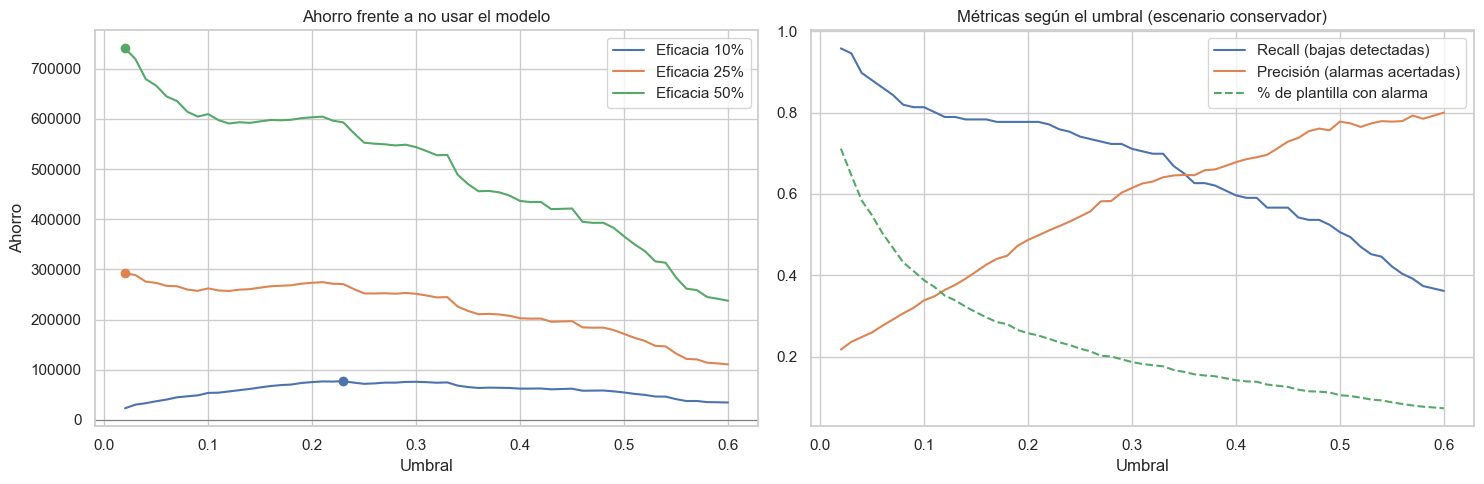

In [78]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Ahorro según el umbral en cada escenario
for e, t in resultados.items():
    axes[0].plot(t['umbral'], t['ahorro'], label=f'Eficacia {e:.0%}')
    mejor = t.loc[t['ahorro'].idxmax()]
    axes[0].scatter(mejor['umbral'], mejor['ahorro'], zorder=3)
axes[0].axhline(0, color='grey', linewidth=0.8)
axes[0].set_title('Ahorro frente a no usar el modelo')
axes[0].set_xlabel('Umbral')
axes[0].set_ylabel('Ahorro')
axes[0].legend()

# Recall, precisión y % de plantilla con alarma según el umbral
t = resultados[cu['eficacia_elegida']]
axes[1].plot(t['umbral'], t['recall'], label='Recall (bajas detectadas)')
axes[1].plot(t['umbral'], t['precision'], label='Precisión (alarmas acertadas)')
axes[1].plot(t['umbral'], t['pct_plantilla'] / 100, label='% de plantilla con alarma', linestyle='--')
axes[1].set_title('Métricas según el umbral (escenario conservador)')
axes[1].set_xlabel('Umbral')
axes[1].legend()

plt.tight_layout()
plt.savefig(FIG_DIR / '06_eleccion_umbral.png', dpi=150, bbox_inches='tight')
plt.show()

In [79]:
# Umbral elegido: el óptimo del escenario conservador
t_cons = resultados[cu['eficacia_elegida']]
umbral = float(t_cons.loc[t_cons['ahorro'].idxmax(), 'umbral'])
print(f'Umbral elegido: {umbral:.2f}\n')

# Qué parte del ahorro máximo se consigue con ese umbral en cada escenario
comparativa = {}
for e, t in resultados.items():
    ahorro_umbral = t.loc[np.isclose(t['umbral'], umbral), 'ahorro'].iloc[0]
    fila_umbral = t.loc[np.isclose(t['umbral'], umbral)].iloc[0]
    comparativa[f'eficacia {e:.0%}'] = {
        'ahorro_umbral_elegido': ahorro_umbral,
        'ahorro_maximo': t['ahorro'].max(),
        '%_del_maximo': ahorro_umbral / t['ahorro'].max() * 100,
        'alarmas_umbral_elegido': fila_umbral['alarmas'],
        'alarmas_en_el_maximo': t.loc[t['ahorro'].idxmax(), 'alarmas'],
    }
pd.DataFrame(comparativa).T.round(1)

Umbral elegido: 0.23



,ahorro_umbral_elegido,ahorro_maximo,%_del_maximo,alarmas_umbral_elegido,alarmas_en_el_maximo
eficacia 10%,77353.0,77353.0,100.0,242.0,242.0
eficacia 25%,270783.2,292312.5,92.6,242.0,732.0
eficacia 50%,593166.8,740705.7,80.1,242.0,732.0


**Resultado:**

**Resultado:**

El coste medio de perder a uno de los empleados que abandonan la empresa es de 11.635 unidades monetarias (el dataset no especifica la moneda), frente a 213 de una conversación: cada baja cuesta unas 55 veces más que una alarma. Este coste es inferior a la media de toda la plantilla (15.716), ya que los empleados que se van tienen salarios más bajos. Las probabilidades fuera de partición tienen una media de 0,162, prácticamente igual a la tasa real de bajas (0,161), lo que indica que el modelo no sobrestima ni subestima el riesgo en conjunto.

| Escenario de eficacia | Umbral óptimo | Alarmas en el óptimo | Ahorro con umbral 0,23 | % del ahorro máximo |
|---|---|---|---|---|
| 10 % (conservador) | 0,23 | 242 | 77.353 | 100 % |
| 25 % (intermedio) | 0,02 | 732 | 270.783 | 92,6 % |
| 50 % (optimista) | 0,02 | 732 | 593.167 | 80,1 % |

- En el **escenario conservador**, el ahorro es máximo con un umbral de **0,23**. Con él se genera una alarma para el 24 % de los empleados (242 de 1.029), se detecta el 76 % de las bajas y algo más de la mitad de las alarmas (52 %) corresponde a empleados que efectivamente se van.
- En los **escenarios intermedio y optimista**, el ahorro máximo se alcanza con el umbral más bajo analizado, que supone generar alarmas para el 71 % de la plantilla. Cuanto más eficaz es la conversación, más compensa extenderla a casi todos los empleados, dada la gran diferencia entre el coste de una baja y el de una conversación.
- Sin embargo, la curva de ahorro es muy plana en ese tramo: con el umbral de 0,23 se obtiene el 92,6 % del ahorro máximo en el escenario intermedio y el 80,1 % en el optimista, con solo un tercio de las conversaciones (242 frente a 732).

**Decisión:** se adopta un umbral de **0,23**. Es el óptimo en el escenario más prudente, mantiene la mayor parte del ahorro en los escenarios más favorables y genera un volumen de conversaciones asumible para la organización. La elección prioriza la detección de bajas (*recall*) frente a la precisión, de acuerdo con la diferencia de costes entre ambos tipos de error.

Los escenarios favorables sugieren, además, que si las conversaciones resultan eficaces, la práctica recomendable sería extenderlas progresivamente a toda la plantilla. En ese caso, el modelo serviría para **priorizar** a qué empleados atender primero.

Estas cifras se han obtenido sobre el conjunto de entrenamiento con probabilidades fuera de partición. La evaluación definitiva del modelo con este umbral se realiza sobre el conjunto de test en el apartado 4.

### 3.3. Entrenamiento y guardado del modelo final

El modelo seleccionado se entrena con el conjunto de entrenamiento completo y se guarda en la carpeta `models/`, junto con un fichero de metadatos que recoge la variante elegida, el umbral de decisión y las métricas obtenidas en validación cruzada. El pipeline guardado incluye todas las etapas (construcción de variables, codificación, escalado y regresión logística), por lo que puede aplicarse directamente a nuevos datos con el mismo formato que el dataset original.

In [80]:
import json
import joblib

modelo_final.fit(X_train, y_train)

dir_modelos = ROOT / config['paths']['models']
joblib.dump(modelo_final, dir_modelos / 'modelo_final.joblib')

metadatos = {
    'variante': config['model']['variante_final'],
    'umbral': umbral,
    'auc_cv': round(float(comparacion.loc['log_sin_sensibles_indice', 'auc_media']), 4),
    'brier_cv': round(float(comparacion.loc['log_sin_sensibles_indice', 'brier_media']), 4),
    'n_train': int(len(X_train)),
}
with open(dir_modelos / 'metadatos.json', 'w', encoding='utf-8') as f:
    json.dump(metadatos, f, indent=2, ensure_ascii=False)

print(f'Variables que utiliza el modelo: {modelo_final[-1].coef_.shape[1]}')
print('Archivos guardados en models/:', [p.name for p in dir_modelos.iterdir()])

Variables que utiliza el modelo: 31
Archivos guardados en models/: ['metadatos.json', 'modelo_final.joblib']


**Resultado:** el modelo final, entrenado con los 1.029 empleados del conjunto de entrenamiento, utiliza 31 variables tras el preprocesado. El pipeline completo se ha guardado en `models/modelo_final.joblib` y la variante, el umbral (0,23) y las métricas de validación cruzada en `models/metadatos.json`.

## 4. Evaluación del modelo en el conjunto de test

El modelo final se evalúa sobre los 441 empleados del conjunto de test, que no se han utilizado en ninguna decisión anterior (selección de variables, comparación de variantes ni elección del umbral). Esta evaluación se realiza una única vez y proporciona una estimación realista del rendimiento del modelo con empleados nuevos.

### 4.1. Matriz de confusión

La matriz de confusión compara la predicción del modelo con la realidad y clasifica a cada empleado en uno de cuatro grupos:

- **Verdaderos negativos (VN)**: empleados que permanecen y para los que el modelo no genera alarma.
- **Falsos positivos (FP)**: empleados que permanecen, pero para los que el modelo genera una alarma (falsas alarmas).
- **Falsos negativos (FN)**: empleados que se van sin que el modelo lo detecte (bajas no detectadas).
- **Verdaderos positivos (VP)**: empleados que se van y para los que el modelo genera una alarma (bajas detectadas).

Se presentan dos matrices: con el umbral por defecto de 0,5 y con el umbral de 0,23 elegido en el apartado 3.2, para mostrar cómo cambia el reparto de aciertos y errores al modificar el umbral.

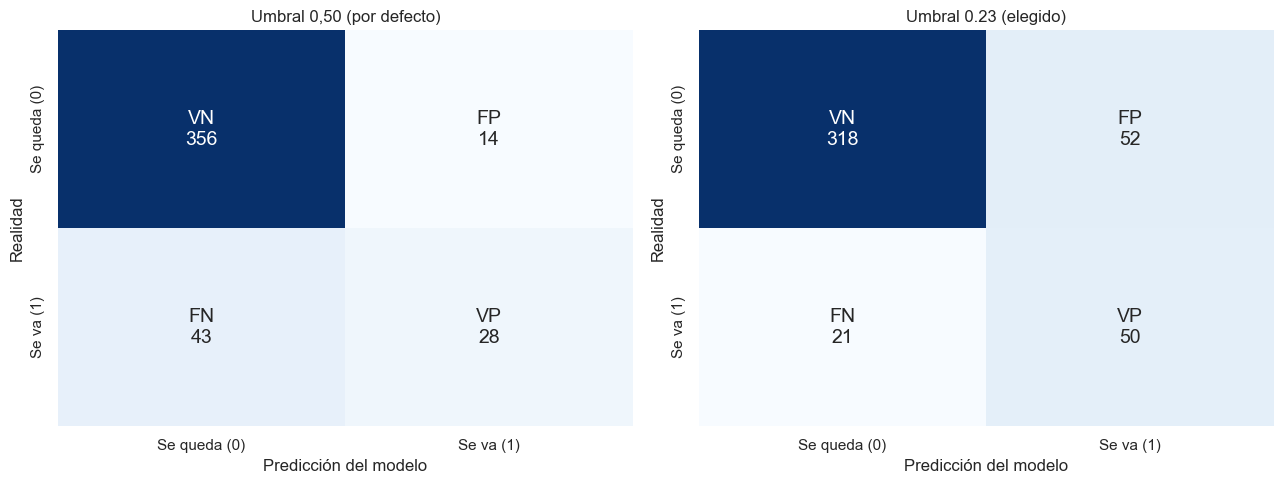

Umbral 0,50: VN = 356 | FP = 14 | FN = 43 | VP = 28
Umbral 0.23: VN = 318 | FP = 52 | FN = 21 | VP = 50


In [81]:
from sklearn.metrics import confusion_matrix

# Probabilidad de baja estimada para cada empleado del test
prob_test = modelo_final.predict_proba(X_test)[:, 1]

pred_05 = (prob_test >= 0.5).astype(int)
pred_umbral = (prob_test >= umbral).astype(int)

cm_05 = confusion_matrix(y_test, pred_05)
cm_umbral = confusion_matrix(y_test, pred_umbral)

etiquetas = ['Se queda (0)', 'Se va (1)']
nombres = np.array([['VN', 'FP'], ['FN', 'VP']])

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, cm, titulo in zip(axes, [cm_05, cm_umbral],
                          ['Umbral 0,50 (por defecto)', f'Umbral {umbral:.2f} (elegido)']):
    anotaciones = np.array([[f'{nombres[i, j]}\n{cm[i, j]}' for j in range(2)] for i in range(2)])
    sns.heatmap(cm, annot=anotaciones, fmt='', cmap='Blues', cbar=False,
                xticklabels=etiquetas, yticklabels=etiquetas, ax=ax, annot_kws={'size': 14})
    ax.set_xlabel('Predicción del modelo')
    ax.set_ylabel('Realidad')
    ax.set_title(titulo)

plt.tight_layout()
plt.savefig(FIG_DIR / '07_matrices_confusion.png', dpi=150, bbox_inches='tight')
plt.show()

for nombre, cm in [('0,50', cm_05), (f'{umbral:.2f}', cm_umbral)]:
    vn, fp, fn, vp = cm.ravel()
    print(f'Umbral {nombre}: VN = {vn} | FP = {fp} | FN = {fn} | VP = {vp}')

### 4.2. Métricas de clasificación

A partir de los cuatro valores de la matriz de confusión se calculan las métricas de evaluación:

- **Accuracy** = (VP + VN) / Total. Proporción de empleados clasificados correctamente. Con clases desbalanceadas es engañosa: predecir siempre que nadie se va obtendría un 83,9 % en este test (370 de 441) sin detectar ninguna baja.
- **Precisión** = VP / (VP + FP). De las alarmas generadas, qué proporción corresponde a empleados que realmente se van.
- **Recall o sensibilidad** = VP / (VP + FN). De los empleados que se van, qué proporción detecta el modelo. Es la métrica prioritaria en este caso.
- **Especificidad** = VN / (VN + FP). De los empleados que permanecen, qué proporción no recibe una alarma.
- **Tasa de falsas alarmas** = FP / (FP + VN) = 1 − especificidad. Proporción de empleados que permanecen y reciben una alarma. Junto con el recall, es la base de la curva ROC.
- **F1** = 2 · Precisión · Recall / (Precisión + Recall). Media armónica de precisión y recall, que resume el equilibrio entre ambas.

Las métricas se calculan directamente con estas fórmulas y se comprueba que coinciden con las que proporciona scikit-learn.

In [82]:
def metricas_a_mano(cm):
    """Calcula las métricas de clasificación a partir de la matriz de confusión."""
    vn, fp, fn, vp = cm.ravel()
    total = vn + fp + fn + vp
    precision = vp / (vp + fp)
    recall = vp / (vp + fn)
    return {
        'Accuracy = (VP+VN) / Total': (vp + vn) / total,
        'Precisión = VP / (VP+FP)': precision,
        'Recall = VP / (VP+FN)': recall,
        'Especificidad = VN / (VN+FP)': vn / (vn + fp),
        'Tasa de falsas alarmas = FP / (FP+VN)': fp / (fp + vn),
        'F1 = 2·P·R / (P+R)': 2 * precision * recall / (precision + recall),
        'Nº de alarmas = VP+FP': vp + fp,
    }


tabla_metricas = pd.DataFrame({
    'Umbral 0,50': metricas_a_mano(cm_05),
    f'Umbral {umbral:.2f}': metricas_a_mano(cm_umbral),
}).round(3)
tabla_metricas

,"Umbral 0,50",Umbral 0.23
Accuracy = (VP+VN) / Total,0.871,0.834
Precisión = VP / (VP+FP),0.667,0.490
Recall = VP / (VP+FN),0.394,0.704
Especificidad = VN / (VN+FP),0.962,0.859
Tasa de falsas alarmas = FP / (FP+VN),0.038,0.141
F1 = 2·P·R / (P+R),0.496,0.578
Nº de alarmas = VP+FP,42.000,102.000


In [83]:
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score

for nombre, pred in [('0,50', pred_05), (f'{umbral:.2f}', pred_umbral)]:
    print(f'Umbral {nombre} (sklearn): '
          f'accuracy = {accuracy_score(y_test, pred):.3f} | '
          f'precisión = {precision_score(y_test, pred):.3f} | '
          f'recall = {recall_score(y_test, pred):.3f} | '
          f'F1 = {f1_score(y_test, pred):.3f}')

Umbral 0,50 (sklearn): accuracy = 0.871 | precisión = 0.667 | recall = 0.394 | F1 = 0.496
Umbral 0.23 (sklearn): accuracy = 0.834 | precisión = 0.490 | recall = 0.704 | F1 = 0.578


**Resultado:**

| Métrica | Umbral 0,50 | Umbral 0,23 (elegido) |
|---|---|---|
| Verdaderos negativos (VN) | 356 | 318 |
| Falsos positivos (FP) | 14 | 52 |
| Falsos negativos (FN) | 43 | 21 |
| Verdaderos positivos (VP) | 28 | 50 |
| Accuracy | 0,871 | 0,834 |
| Precisión | 0,667 | 0,490 |
| **Recall** | 0,394 | **0,704** |
| Especificidad | 0,962 | 0,859 |
| Tasa de falsas alarmas | 0,038 | 0,141 |
| F1 | 0,496 | 0,578 |
| Nº de alarmas | 42 | 102 |

Las métricas calculadas a partir de la matriz de confusión coinciden con las de scikit-learn.

- **Con el umbral por defecto (0,50)**, el modelo clasifica correctamente al 87,1 % de los empleados, pero solo detecta 28 de las 71 bajas (*recall* de 0,39): seis de cada diez empleados que se van no reciben ninguna alarma. Para el objetivo de retención, este umbral no resulta útil.
- **Con el umbral elegido (0,23)**, el modelo detecta 50 de las 71 bajas (*recall* de 0,70). A cambio, las falsas alarmas aumentan de 14 a 52: para detectar 22 bajas adicionales se generan 38 alarmas más, menos de dos conversaciones adicionales por cada baja detectada. Dado que cada baja cuesta unas 55 veces más que una conversación, el intercambio es claramente favorable.
- **La accuracy no refleja la utilidad del modelo.** Con el umbral elegido es del 83,4 %, inferior incluso al 83,9 % que se obtendría prediciendo que ningún empleado se va. Sin embargo, esa predicción trivial no detectaría ninguna baja, mientras que el modelo detecta el 70 %. Esto confirma que, con clases desbalanceadas, la accuracy no es una métrica adecuada.
- **La precisión (0,49)** indica que aproximadamente una de cada dos alarmas corresponde a un empleado que efectivamente se va. Teniendo en cuenta que solo el 16,1 % de la plantilla abandona la empresa, el grupo señalado concentra tres veces más bajas que un grupo elegido al azar.
- **La especificidad (0,86)** indica que el 86 % de los empleados que permanecen no recibe ninguna alarma.

**Generalización.** Los resultados en el test son coherentes con los estimados en el conjunto de entrenamiento mediante probabilidades fuera de partición (*recall* de 0,76, precisión de 0,52 y alarmas para el 24 % de la plantilla, frente a 0,70, 0,49 y 23 % en el test). La ligera disminución es la esperable al aplicar el modelo a datos nuevos e indica que no existe sobreajuste relevante.

### 4.3. Curva ROC

La curva ROC representa, para todos los umbrales posibles, la proporción de bajas detectadas (*recall*, eje vertical) frente a la tasa de falsas alarmas (1 − especificidad, eje horizontal). Cada punto de la curva corresponde, por tanto, a una matriz de confusión distinta. La diagonal representa un modelo que asigna el riesgo al azar; cuanto más se aleje la curva hacia la esquina superior izquierda, mejor distingue el modelo entre quienes se van y quienes permanecen.

El área bajo la curva (AUC) resume esta capacidad en un único valor entre 0,5 (azar) y 1 (separación perfecta). Puede interpretarse como la probabilidad de que, tomando al azar un empleado que se va y otro que permanece, el modelo asigne mayor riesgo al primero. Sobre la curva se señalan los puntos correspondientes al umbral por defecto (0,50) y al umbral elegido (0,23).

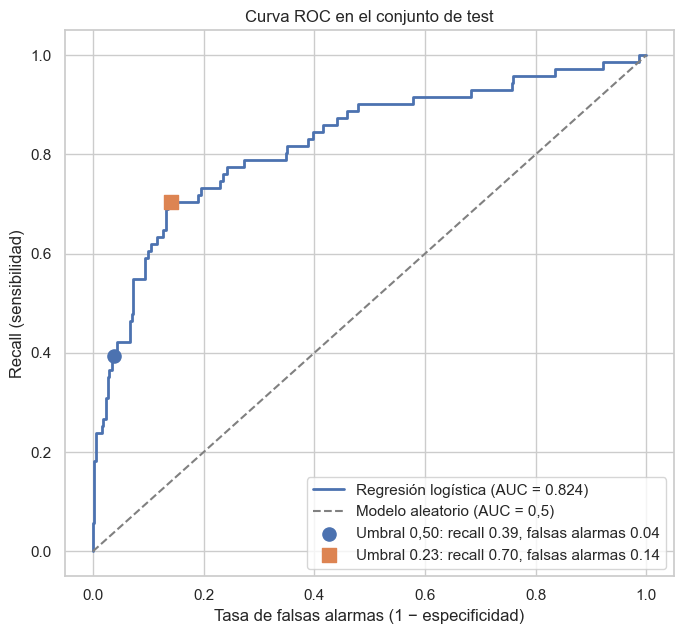

AUC en test: 0.824 | AUC en validación cruzada: 0.865


In [84]:
from sklearn.metrics import roc_auc_score, roc_curve

fpr, tpr, _ = roc_curve(y_test, prob_test)
auc_test = roc_auc_score(y_test, prob_test)

fig, ax = plt.subplots(figsize=(7, 6.5))
ax.plot(fpr, tpr, linewidth=2, label=f'Regresión logística (AUC = {auc_test:.3f})')
ax.plot([0, 1], [0, 1], linestyle='--', color='grey', label='Modelo aleatorio (AUC = 0,5)')

for nombre, cm, marcador in [('0,50', cm_05, 'o'), (f'{umbral:.2f}', cm_umbral, 's')]:
    vn, fp, fn, vp = cm.ravel()
    x_pt, y_pt = fp / (fp + vn), vp / (vp + fn)
    ax.scatter(x_pt, y_pt, s=90, marker=marcador, zorder=3,
               label=f'Umbral {nombre}: recall {y_pt:.2f}, falsas alarmas {x_pt:.2f}')

ax.set_xlabel('Tasa de falsas alarmas (1 − especificidad)')
ax.set_ylabel('Recall (sensibilidad)')
ax.set_title('Curva ROC en el conjunto de test')
ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig(FIG_DIR / '08_curva_roc.png', dpi=150, bbox_inches='tight')
plt.show()

print(f'AUC en test: {auc_test:.3f} | AUC en validación cruzada: {metadatos["auc_cv"]:.3f}')

**Cálculo del AUC.** Para comprobar el valor obtenido, el AUC se calcula de dos formas. La primera reconstruye la curva umbral a umbral (calculando el *recall* y la tasa de falsas alarmas de cada matriz de confusión) y suma el área bajo ella mediante trapecios. La segunda forma todas las parejas posibles de un empleado que se va y otro que permanece (71 × 370 = 26.270) y calcula la proporción en que el modelo asigna mayor probabilidad al que se va, contando los empates como medio acierto. Ambos cálculos deben coincidir con el valor de scikit-learn.

In [85]:
yt = y_test.to_numpy()

# Forma 1: construir la curva umbral a umbral y calcular el área (trapecios)
puntos = [(0.0, 0.0)]
for u in np.sort(np.unique(prob_test))[::-1]:
    alarma = prob_test >= u
    vp = (alarma & (yt == 1)).sum()
    fn = (~alarma & (yt == 1)).sum()
    fp = (alarma & (yt == 0)).sum()
    vn = (~alarma & (yt == 0)).sum()
    puntos.append((fp / (fp + vn), vp / (vp + fn)))
x_roc, y_roc = np.array(puntos).T
auc_area = np.trapezoid(y_roc, x_roc)

# Forma 2: proporción de parejas (se va, se queda) bien ordenadas
p_se_va = prob_test[yt == 1]
p_se_queda = prob_test[yt == 0]
diferencias = p_se_va[:, None] - p_se_queda[None, :]
auc_parejas = ((diferencias > 0).sum() + 0.5 * (diferencias == 0).sum()) / diferencias.size

print(f'Parejas comparadas: {diferencias.size}')
print(f'AUC por área bajo la curva: {auc_area:.3f}')
print(f'AUC por parejas:            {auc_parejas:.3f}')
print(f'AUC de scikit-learn:        {auc_test:.3f}')

Parejas comparadas: 26270
AUC por área bajo la curva: 0.824
AUC por parejas:            0.824
AUC de scikit-learn:        0.824


**Resultado:** el modelo obtiene un **AUC de 0,824** en el conjunto de test: tomando al azar un empleado que se va y otro que permanece, el modelo asigna mayor riesgo al primero en el 82,4 % de los casos. El cálculo a mano, tanto por el área bajo la curva como por comparación de las 26.270 parejas posibles, coincide con el valor de scikit-learn. La curva se sitúa claramente por encima de la diagonal en todo su recorrido, lo que indica una buena capacidad de discriminación.

El AUC en el test es algo inferior al estimado en validación cruzada (0,865). La diferencia (0,04) es similar a la variabilidad observada entre particiones en la validación cruzada (desviación típica de 0,032) y es esperable, ya que el test contiene solo 71 bajas y su resultado depende en parte de qué empleados hayan quedado en él.

Los dos umbrales analizados ocupan posiciones distintas sobre la curva. El umbral de 0,50 se sitúa en la zona inferior izquierda: apenas genera falsas alarmas (4 %), pero solo detecta el 39 % de las bajas. El umbral elegido de 0,23 se sitúa en el "codo" de la curva, con un 70 % de bajas detectadas y un 14 % de falsas alarmas. A partir de ese punto la curva se aplana: detectar un 80 % de las bajas exigiría elevar las falsas alarmas hasta cerca del 35 %. Aunque el umbral se eligió mediante el análisis de costes, su posición en la curva confirma que se encuentra en la zona de mejor equilibrio entre detección y falsas alarmas.

### 4.4. Calibración de las probabilidades

Además de ordenar correctamente a los empleados según su riesgo, el modelo debe proporcionar probabilidades fiables: si asigna un 30 % de riesgo a un grupo de empleados, aproximadamente el 30 % de ese grupo debería abandonar la empresa. Esto es especialmente relevante si las probabilidades se comunican a RRHH o se utilizan para estimar el número de bajas esperado.

Para comprobarlo, los empleados del test se dividen en cinco grupos de igual tamaño según su probabilidad estimada, y en cada uno se compara la probabilidad media del modelo con la proporción real de bajas. Se utilizan cinco grupos porque, con 71 bajas en el test, un número mayor daría lugar a proporciones muy inestables. Si el modelo está bien calibrado, los puntos se sitúan sobre la diagonal.

Se calcula también el Brier score en el test y se compara con el de un modelo de referencia que asigna a todos los empleados la tasa media de bajas, mediante el *Brier skill score* (1 − Brier del modelo / Brier de referencia), que vale 0 si el modelo no mejora la referencia y 1 si sus predicciones son perfectas.

,n,bajas,prob_media,tasa_real
"(-0.000835, 0.0096]",89,3,0.004,0.034
"(0.0096, 0.0318]",88,4,0.018,0.045
"(0.0318, 0.0736]",88,8,0.051,0.091
"(0.0736, 0.262]",88,11,0.158,0.125
"(0.262, 0.994]",88,45,0.540,0.511


Brier score en test: 0.0980 | Brier en validación cruzada: 0.0840
Brier de referencia (tasa media para todos): 0.1351
Brier skill score: 0.274


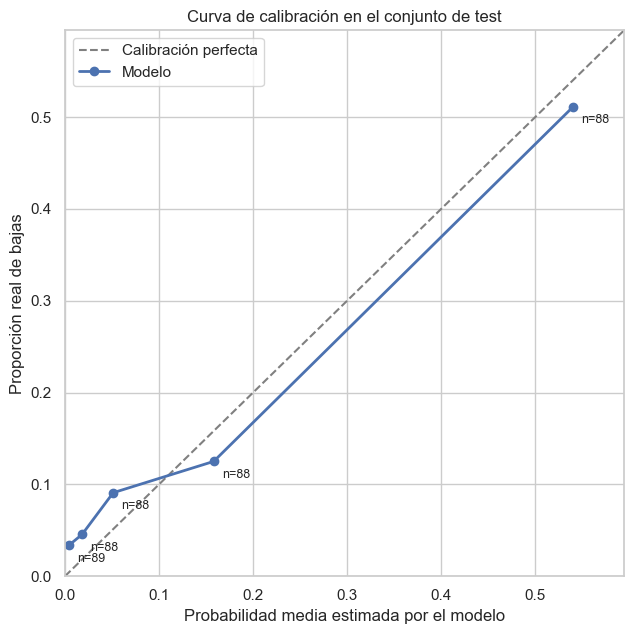

In [86]:
from sklearn.metrics import brier_score_loss

# Tabla de calibración: 5 grupos de igual tamaño según la probabilidad estimada
grupos = pd.qcut(prob_test, q=5)
tabla_cal = (pd.DataFrame({'prob': prob_test, 'baja': yt})
             .groupby(grupos, observed=True)
             .agg(n=('baja', 'size'), bajas=('baja', 'sum'),
                  prob_media=('prob', 'mean'), tasa_real=('baja', 'mean')))
display(tabla_cal.round(3))

# Brier score del modelo y de la referencia (todos con la tasa media de bajas)
brier_test = brier_score_loss(y_test, prob_test)
tasa = y_test.mean()
brier_ref = tasa * (1 - tasa)
print(f'Brier score en test: {brier_test:.4f} | Brier en validación cruzada: {metadatos["brier_cv"]:.4f}')
print(f'Brier de referencia (tasa media para todos): {brier_ref:.4f}')
print(f'Brier skill score: {1 - brier_test / brier_ref:.3f}')

# Curva de calibración
limite = max(tabla_cal['prob_media'].max(), tabla_cal['tasa_real'].max()) * 1.1
fig, ax = plt.subplots(figsize=(6.5, 6.5))
ax.plot([0, limite], [0, limite], linestyle='--', color='grey', label='Calibración perfecta')
ax.plot(tabla_cal['prob_media'], tabla_cal['tasa_real'], marker='o', linewidth=2, label='Modelo')
for _, fila in tabla_cal.iterrows():
    ax.annotate(f"n={int(fila['n'])}", (fila['prob_media'], fila['tasa_real']),
                textcoords='offset points', xytext=(6, -12), fontsize=9)
ax.set_xlim(0, limite)
ax.set_ylim(0, limite)
ax.set_xlabel('Probabilidad media estimada por el modelo')
ax.set_ylabel('Proporción real de bajas')
ax.set_title('Curva de calibración en el conjunto de test')
ax.legend(loc='upper left')
plt.tight_layout()
plt.savefig(FIG_DIR / '09_calibracion.png', dpi=150, bbox_inches='tight')
plt.show()

**Resultado:**

| Grupo de riesgo | Empleados | Bajas | Probabilidad media estimada | Proporción real de bajas |
|---|---|---|---|---|
| 1 (más bajo) | 89 | 3 | 0,4 % | 3,4 % |
| 2 | 88 | 4 | 1,8 % | 4,5 % |
| 3 | 88 | 8 | 5,1 % | 9,1 % |
| 4 | 88 | 11 | 15,8 % | 12,5 % |
| 5 (más alto) | 88 | 45 | 54,0 % | 51,1 % |

- **El grupo de mayor riesgo está bien calibrado**: el modelo estima una probabilidad media del 54,0 % y abandona la empresa el 51,1 %. Es el grupo que concentra la mayoría de las alarmas, por lo que sus probabilidades pueden comunicarse a RRHH con confianza.
- **En los grupos de menor riesgo, el modelo infraestima ligeramente la probabilidad de baja**: asigna entre un 0,4 % y un 5,1 %, mientras que la proporción real se sitúa entre el 3,4 % y el 9,1 %. Las diferencias son de pocos puntos y se basan en muy pocas bajas (entre 3 y 8 por grupo), por lo que están sujetas a una variabilidad considerable. En términos prácticos, indican que un riesgo bajo no equivale a un riesgo nulo.
- **Brier score.** En el test es de 0,098, frente a 0,084 en validación cruzada, una diferencia coherente con la observada en el AUC. El modelo reduce en un 27 % el error de un modelo de referencia que asigna a todos los empleados la tasa media de bajas (*Brier skill score* de 0,27). Este nivel de mejora es razonable para un fenómeno como la rotación, que depende en parte de factores no recogidos en los datos (ofertas externas, circunstancias personales), lo que impide predicciones cercanas a 0 o 1 para la mayoría de los empleados.

En conjunto, el modelo está razonablemente bien calibrado, consecuencia de haberlo entrenado sin reponderar las clases. No se ha aplicado ningún método de recalibración, ya que las desviaciones observadas son pequeñas y, con el tamaño del test, corregirlas implicaría riesgo de ajustarse al ruido.

### 4.5. Registro del modelo final

El modelo final se registra en MLflow junto con su configuración (variante y umbral), las métricas obtenidas en validación cruzada y en el conjunto de test, el propio modelo y los gráficos generados. Las métricas de test se añaden también al fichero de metadatos del modelo. De este modo, el experimento queda documentado de forma completa y reproducible.

In [87]:
import mlflow

vn, fp, fn, vp = cm_umbral.ravel()
metricas_test = {
    'auc_test': float(auc_test),
    'brier_test': float(brier_test),
    'recall_test': float(vp / (vp + fn)),
    'precision_test': float(vp / (vp + fp)),
    'especificidad_test': float(vn / (vn + fp)),
    'alarmas_test': int(vp + fp),
}

# Se añaden las métricas de test a los metadatos del modelo
metadatos['metricas_test'] = {k: round(v, 4) for k, v in metricas_test.items()}
with open(dir_modelos / 'metadatos.json', 'w', encoding='utf-8') as f:
    json.dump(metadatos, f, indent=2, ensure_ascii=False)

with mlflow.start_run(run_name='modelo_final'):
    mlflow.log_params({**config['model']['variante_final'],
                       'umbral': umbral,
                       'eficacia_supuesta': cu['eficacia_elegida']})
    mlflow.log_metrics({'auc_cv': metadatos['auc_cv'],
                        'brier_cv': metadatos['brier_cv'],
                        **metricas_test})
    mlflow.log_artifact(str(dir_modelos / 'modelo_final.joblib'), artifact_path='modelo')
    mlflow.log_artifact(str(dir_modelos / 'metadatos.json'), artifact_path='modelo')
    mlflow.log_artifacts(str(FIG_DIR), artifact_path='figuras')

print('Modelo final registrado en MLflow.')
print(json.dumps(metadatos, indent=2, ensure_ascii=False))

Modelo final registrado en MLflow.
{
  "variante": {
    "nuevas_variables": true,
    "solo_indice": true,
    "excluir_sensibles": true,
    "log_asimetricas": true
  },
  "umbral": 0.23,
  "auc_cv": 0.8652,
  "brier_cv": 0.084,
  "n_train": 1029,
  "metricas_test": {
    "auc_test": 0.8241,
    "brier_test": 0.098,
    "recall_test": 0.7042,
    "precision_test": 0.4902,
    "especificidad_test": 0.8595,
    "alarmas_test": 102
  }
}


**Resultado:** el modelo final queda registrado en MLflow junto con los siete experimentos de comparación de variantes. El fichero `models/metadatos.json` recoge la configuración del modelo y sus métricas: AUC de 0,865 y Brier de 0,084 en validación cruzada, y AUC de 0,824, Brier de 0,098, *recall* de 0,70, precisión de 0,49 y especificidad de 0,86 en el conjunto de test, con 102 alarmas sobre 441 empleados.

## 5. Interpretación del modelo

### 5.1. Odds ratios

En la regresión logística, cada coeficiente indica cómo cambia el logaritmo de las *odds* de baja (la probabilidad de irse dividida entre la de quedarse) cuando aumenta la variable correspondiente, manteniendo constantes las demás. Su exponencial, el ***odds ratio*** (OR), expresa por cuánto se multiplican las *odds*: un OR mayor que 1 indica que la variable aumenta el riesgo de baja, y uno menor que 1, que lo reduce. Su interpretación depende del tipo de variable:

- **Variables binarias**: compara tener la característica frente a no tenerla (por ejemplo, hacer horas extra frente a no hacerlas).
- **Variables *dummy***: compara cada categoría con la de referencia (*Sales Executive*, *Life Sciences*).
- **Variables numéricas y ordinales**: indica el efecto de aumentar la variable en una desviación típica. Para facilitar la lectura, se indica a cuánto equivale una desviación típica en las unidades originales.
- **Variables con transformación logarítmica** (años de experiencia, en la empresa, en el puesto, desde el último ascenso y con el responsable actual): el efecto de un aumento de una desviación típica en escala logarítmica, lo que implica que cada año adicional pesa más en los primeros años que en los siguientes.

Para obtener intervalos de confianza y contrastes de significación, el modelo se reajusta con la librería `statsmodels` sobre las mismas variables ya preprocesadas. A diferencia de scikit-learn, esta estimación no aplica regularización, por lo que se comparan ambos coeficientes para comprobar que la diferencia es pequeña. Se considera que el efecto de una variable es estadísticamente significativo si su intervalo de confianza del 95 % no incluye el valor 1.

In [88]:
import statsmodels.api as sm

# Datos de entrenamiento ya preprocesados con el pipeline final (ajustado con train)
X_train_final = modelo_final[:-1].transform(X_train)

logit = sm.Logit(y_train, sm.add_constant(X_train_final)).fit(disp=0)
ic = logit.conf_int()

odds = pd.DataFrame({
    'OR': np.exp(logit.params),
    'IC95_inf': np.exp(ic[0]),
    'IC95_sup': np.exp(ic[1]),
    'p_valor': logit.pvalues,
    'coef_statsmodels': logit.params,
}).drop(index='const')
odds['coef_sklearn'] = modelo_final[-1].coef_[0]

# Equivalencia de una desviación típica en unidades originales (variables escaladas sin logaritmo)
escalador = modelo_final.named_steps['preprocesado'].named_transformers_['num']
odds['1_DT_equivale_a'] = pd.Series(escalador.scale_, index=escalador.feature_names_in_)

odds = odds.sort_values('OR', ascending=False).round(3)
print(f'Pseudo R² de McFadden: {logit.prsquared:.3f}')
odds

Pseudo R² de McFadden: 0.404


,OR,IC95_inf,IC95_sup,p_valor,coef_statsmodels,coef_sklearn,1_DT_equivale_a
OverTime_Yes,7.654,4.682,12.512,0.000,2.035,1.829,NaN
EducationField_Human Resources,2.987,0.484,18.456,0.239,1.094,0.600,NaN
NumInsatisfaccion,2.403,1.912,3.020,0.000,0.877,0.819,0.737
JobRole_Sales Representative,2.175,0.765,6.185,0.145,0.777,0.643,NaN
EducationField_Technical Degree,2.114,0.988,4.523,0.054,0.748,0.592,NaN
NumCompaniesWorked,1.830,1.436,2.334,0.000,0.605,0.572,2.496
YearsSinceLastPromotion,1.791,1.327,2.418,0.000,0.583,0.541,NaN
BusinessTravel,1.716,1.348,2.185,0.000,0.540,0.489,NaN
DistanceFromHome,1.516,1.219,1.886,0.000,0.416,0.387,8.157
JobRole_Laboratory Technician,1.387,0.602,3.198,0.443,0.327,0.350,NaN


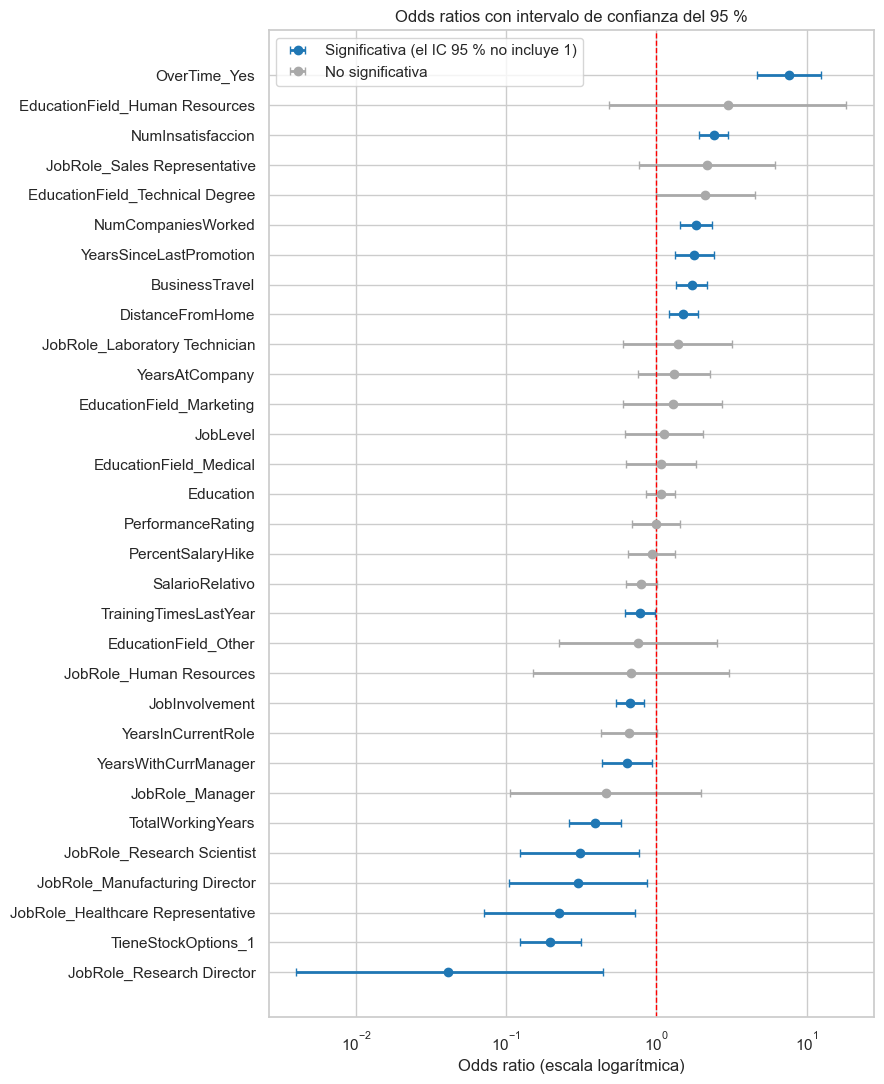

In [89]:
significativa = (odds['IC95_inf'] > 1) | (odds['IC95_sup'] < 1)
orden = odds.sort_values('OR')
posiciones = np.arange(len(orden))

fig, ax = plt.subplots(figsize=(9, 11))
for es_signif, color, etiqueta in [(True, 'tab:blue', 'Significativa (el IC 95 % no incluye 1)'),
                                   (False, 'darkgrey', 'No significativa')]:
    mascara = (significativa[orden.index] == es_signif).to_numpy()
    sub = orden[mascara]
    ax.errorbar(sub['OR'], posiciones[mascara],
                xerr=[sub['OR'] - sub['IC95_inf'], sub['IC95_sup'] - sub['OR']],
                fmt='o', color=color, ecolor=color, elinewidth=2, capsize=3, label=etiqueta)

ax.axvline(1, color='red', linestyle='--', linewidth=1)
ax.set_xscale('log')
ax.set_yticks(posiciones)
ax.set_yticklabels(orden.index)
ax.set_xlabel('Odds ratio (escala logarítmica)')
ax.set_title('Odds ratios con intervalo de confianza del 95 %')
ax.legend(loc='upper left')
plt.tight_layout()
plt.savefig(FIG_DIR / '10_odds_ratios.png', dpi=150, bbox_inches='tight')
plt.show()

In [90]:
import statsmodels.api as sm

# Datos de entrenamiento ya preprocesados con el pipeline final (ajustado con train)
X_train_final = modelo_final[:-1].transform(X_train)

logit = sm.Logit(y_train, sm.add_constant(X_train_final)).fit(disp=0)
ic = logit.conf_int()

odds = pd.DataFrame({
    'OR': np.exp(logit.params),
    'IC95_inf': np.exp(ic[0]),
    'IC95_sup': np.exp(ic[1]),
    'p_valor': logit.pvalues,
    'coef_statsmodels': logit.params,
}).drop(index='const')
odds['coef_sklearn'] = modelo_final[-1].coef_[0]

# Equivalencia de una desviación típica en unidades originales (variables escaladas sin logaritmo)
escalador = modelo_final.named_steps['preprocesado'].named_transformers_['num']
odds['1_DT_equivale_a'] = pd.Series(escalador.scale_, index=escalador.feature_names_in_)

# OR por cada unidad original (un punto, un año, una dimensión...)
odds['OR_por_unidad'] = np.exp(odds['coef_statsmodels'] / odds['1_DT_equivale_a'])

odds = odds.sort_values('OR', ascending=False).round(3)
print(f'Pseudo R² de McFadden: {logit.prsquared:.3f}')
odds

Pseudo R² de McFadden: 0.404


,OR,IC95_inf,IC95_sup,p_valor,coef_statsmodels,coef_sklearn,1_DT_equivale_a,OR_por_unidad
OverTime_Yes,7.654,4.682,12.512,0.000,2.035,1.829,NaN,NaN
EducationField_Human Resources,2.987,0.484,18.456,0.239,1.094,0.600,NaN,NaN
NumInsatisfaccion,2.403,1.912,3.020,0.000,0.877,0.819,0.737,3.284
JobRole_Sales Representative,2.175,0.765,6.185,0.145,0.777,0.643,NaN,NaN
EducationField_Technical Degree,2.114,0.988,4.523,0.054,0.748,0.592,NaN,NaN
NumCompaniesWorked,1.830,1.436,2.334,0.000,0.605,0.572,2.496,1.274
YearsSinceLastPromotion,1.791,1.327,2.418,0.000,0.583,0.541,NaN,NaN
BusinessTravel,1.716,1.348,2.185,0.000,0.540,0.489,NaN,NaN
DistanceFromHome,1.516,1.219,1.886,0.000,0.416,0.387,8.157,1.052
JobRole_Laboratory Technician,1.387,0.602,3.198,0.443,0.327,0.350,NaN,NaN


**Resultado:**

El modelo presenta un pseudo R² de McFadden de 0,40. En este indicador, valores entre 0,2 y 0,4 se consideran representativos de un muy buen ajuste.

Para interpretar los odds ratios en términos de probabilidad, debe tenerse en cuenta que multiplican las *odds* y no la probabilidad. Por ejemplo, un empleado con un 10 % de probabilidad de baja (*odds* de 0,11) que pasara a hacer horas extra (OR = 7,65) tendría unas *odds* de 0,85, equivalentes a una probabilidad del 46 %.

**Factores que aumentan el riesgo de baja** (efectos significativos):
- **Horas extra** (OR = 7,65; IC 95 %: 4,68–12,51): es el factor con mayor efecto del modelo.
- **Insatisfacción**: cada dimensión adicional en el nivel más bajo multiplica las *odds* por 3,3.
- **Número de empresas anteriores**: cada empresa adicional aumenta las *odds* un 27 %. Esta variable no mostraba relación en el análisis exploratorio; el efecto aparece al comparar empleados con la misma experiencia, lo que identifica un perfil de mayor movilidad laboral. Debe interpretarse con cautela por las incoherencias detectadas en la variable.
- **Años desde el último ascenso** (OR = 1,79): en el análisis exploratorio, los empleados que se iban tenían menos años sin ascender, debido a su menor antigüedad. Al controlar por la antigüedad en el modelo multivariante, el efecto se invierte: **a igual antigüedad, más años sin ascenso aumentan el riesgo**, lo que confirma la hipótesis de estancamiento planteada en el preprocesado.
- **Frecuencia de viajes** (OR = 1,72 por desviación típica) y **distancia al domicilio** (un 5 % más de *odds* por cada unidad de distancia).

**Factores que reducen el riesgo de baja** (efectos significativos):
- **Tener stock options** (OR = 0,20): reduce las *odds* de baja en un 80 %.
- **Experiencia total** (OR = 0,39). Esta variable recoge en parte el efecto de la edad, excluida del modelo, con la que está fuertemente relacionada.
- **Implicación en el puesto**: cada punto adicional en la escala reduce las *odds* un 43 %.
- **Formación**: cada formación adicional recibida en el último año las reduce un 18 %.
- **Años con el responsable actual** (OR = 0,64).
- **Puesto**: frente a *Sales Executive*, los puestos de *Research Scientist*, *Healthcare Representative*, *Manufacturing Director* y *Research Director* presentan un riesgo significativamente menor.

**Efectos no significativos destacables:**
- ***Sales Representative*** presentaba la mayor tasa de bajas en el análisis exploratorio (39,8 %), pero su efecto no es significativo en el modelo (IC 95 %: 0,77–6,19). Su elevada rotación se explica por el perfil de sus empleados (menor experiencia y salario, entre otros factores), y no por el puesto en sí.
- **El salario relativo** muestra el efecto esperado (cobrar un 10 % más que la mediana del nivel reduce las *odds* un 9 %), pero se sitúa en el límite de la significación (p = 0,058).
- **`JobLevel`** no es significativo y su coeficiente cambia de signo entre la estimación con y sin regularización, reflejo de la colinealidad con la experiencia y el puesto indicada por su VIF (7,3). Por ello, su coeficiente no se interpreta.

**Comparación entre estimaciones.** Los coeficientes con y sin regularización son muy similares en la mayoría de las variables. Las diferencias más notables se concentran en categorías con pocos empleados (*Research Director*, *Manager* o *Human Resources* en `EducationField`), donde la regularización reduce coeficientes que, sin ella, resultan extremos e imprecisos, como muestra la amplitud de sus intervalos de confianza.

**Precaución.** Los odds ratios describen asociaciones, no relaciones causales: que las horas extra se asocien a un mayor riesgo de baja no demuestra por sí solo que reducirlas vaya a disminuir la rotación, aunque sí identifica una palanca prioritaria para analizar.

### 5.2. Importancia de las variables por permutación

La importancia por permutación mide cuánto depende la capacidad predictiva del modelo de cada variable. Para ello, se desordenan al azar los valores de una variable en el conjunto de test, de modo que pierde su relación con la baja, y se calcula cuánto disminuye el AUC. Cuanto mayor es la disminución, más importante es la variable para el modelo. El proceso se repite 30 veces por variable y se presentan la media y la desviación típica de la disminución.

Esta medida complementa a los odds ratios: mientras estos indican la dirección y la magnitud del efecto de cada variable, la importancia por permutación refleja su contribución real a las predicciones, teniendo en cuenta también cuántos empleados se ven afectados. Al aplicarse sobre el pipeline completo, se permutan las variables originales del dataset, de forma que las variables nominales (como `JobRole`) se evalúan como un todo y es posible medir la contribución de cada escala de satisfacción, aunque el modelo las utilice a través del indicador de insatisfacción. Las variables excluidas del modelo (`Gender`, `MaritalStatus` y `Age`) deben obtener una importancia nula, lo que sirve como comprobación.

In [91]:
from sklearn.inspection import permutation_importance

imp = permutation_importance(modelo_final, X_test, y_test, scoring='roc_auc',
                             n_repeats=30, random_state=config['project']['random_state'])

importancias = (pd.DataFrame({'caida_auc_media': imp.importances_mean,
                              'desviacion': imp.importances_std},
                             index=X_test.columns)
                .sort_values('caida_auc_media', ascending=False)
                .round(4))
importancias

,caida_auc_media,desviacion
OverTime,0.0759,0.0097
MonthlyIncome,0.0693,0.0249
TotalWorkingYears,0.0279,0.0152
StockOptionLevel,0.0273,0.0090
BusinessTravel,0.0225,0.0070
YearsSinceLastPromotion,0.0198,0.0068
NumCompaniesWorked,0.0197,0.0072
JobSatisfaction,0.0185,0.0060
JobInvolvement,0.0132,0.0044
EnvironmentSatisfaction,0.0118,0.0061


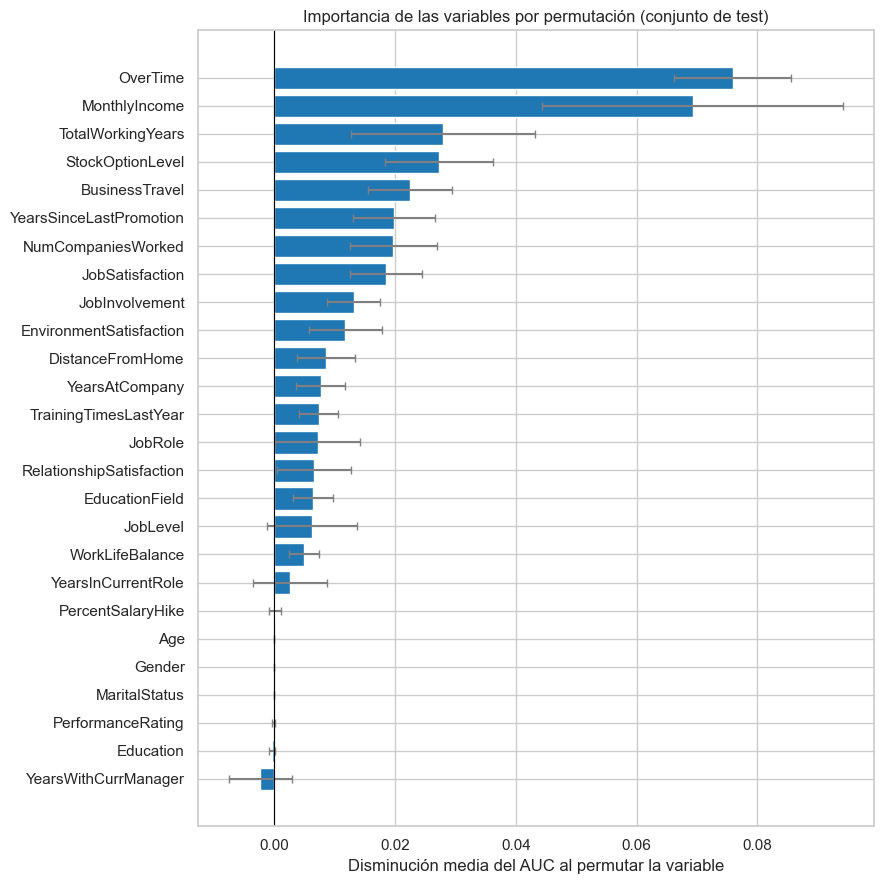

In [92]:
orden_imp = importancias.sort_values('caida_auc_media')

fig, ax = plt.subplots(figsize=(9, 9))
ax.barh(orden_imp.index, orden_imp['caida_auc_media'], xerr=orden_imp['desviacion'],
        color='tab:blue', ecolor='grey', capsize=3)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('Disminución media del AUC al permutar la variable')
ax.set_title('Importancia de las variables por permutación (conjunto de test)')
plt.tight_layout()
plt.savefig(FIG_DIR / '11_importancia_permutacion.png', dpi=150, bbox_inches='tight')
plt.show()

**Limitación del cálculo anterior.** `MonthlyIncome` aparece como la segunda variable más importante, a pesar de que el salario relativo derivado de ella no es significativo en el modelo. Al permutar `MonthlyIncome`, se combinan salarios y niveles jerárquicos de forma arbitraria, lo que genera salarios relativos muy alejados de los observados (por ejemplo, un empleado de nivel 1 con el salario de un directivo alcanzaría un valor de 7,5, frente a un máximo real de 1,87). El modelo debe entonces extrapolar a valores que nunca ha visto, y la caída del AUC refleja esa extrapolación más que la importancia real del salario. Esta es una limitación conocida de la importancia por permutación cuando unas variables se construyen a partir de otras.

Las demás variables no presentan este problema, por lo que el cálculo anterior es válido para ellas. En particular, permite comparar la contribución de cada escala de satisfacción y confirma que las variables sensibles excluidas tienen una importancia nula.

Para obtener una medida fiable de todas las variables, se repite el cálculo permutando directamente las variables que utiliza el modelo, es decir, después de construir el salario relativo, el indicador de insatisfacción y el indicador de stock options.

In [93]:
# Se separa el pipeline: construcción de variables / preprocesado + modelo
n_construccion = len(modelo_final.steps) - 2
construccion = modelo_final[:n_construccion]
resto = modelo_final[n_construccion:]

X_test_construido = construccion.transform(X_test)

imp_modelo = permutation_importance(resto, X_test_construido, y_test, scoring='roc_auc',
                                    n_repeats=30, random_state=config['project']['random_state'])

# Solo las variables que entran realmente en el modelo
pre = modelo_final.named_steps['preprocesado']
usadas = [c for nombre, _, cols in pre.transformers_ if nombre != 'remainder' for c in cols]

importancias_modelo = (pd.DataFrame({'caida_auc_media': imp_modelo.importances_mean,
                                     'desviacion': imp_modelo.importances_std},
                                    index=X_test_construido.columns)
                       .loc[usadas]
                       .sort_values('caida_auc_media', ascending=False)
                       .round(4))
importancias_modelo

c:\Users\Yeray\Desktop\Trabajo People Analytics\rotacion-empleados\.venv\lib\site-packages\sklearn\pipeline.py:61: FutureWarning: This Pipeline instance is not fitted yet. Call 'fit' with appropriate arguments before using other methods such as transform, predict, etc. This will raise an error in 1.8 instead of the current warning.
  warnings.warn(


,caida_auc_media,desviacion
OverTime,0.0759,0.0097
NumInsatisfaccion,0.0486,0.0128
TotalWorkingYears,0.0279,0.0152
TieneStockOptions,0.0273,0.0090
BusinessTravel,0.0225,0.0070
YearsSinceLastPromotion,0.0198,0.0068
NumCompaniesWorked,0.0197,0.0072
JobInvolvement,0.0132,0.0044
DistanceFromHome,0.0086,0.0048
YearsAtCompany,0.0077,0.0041


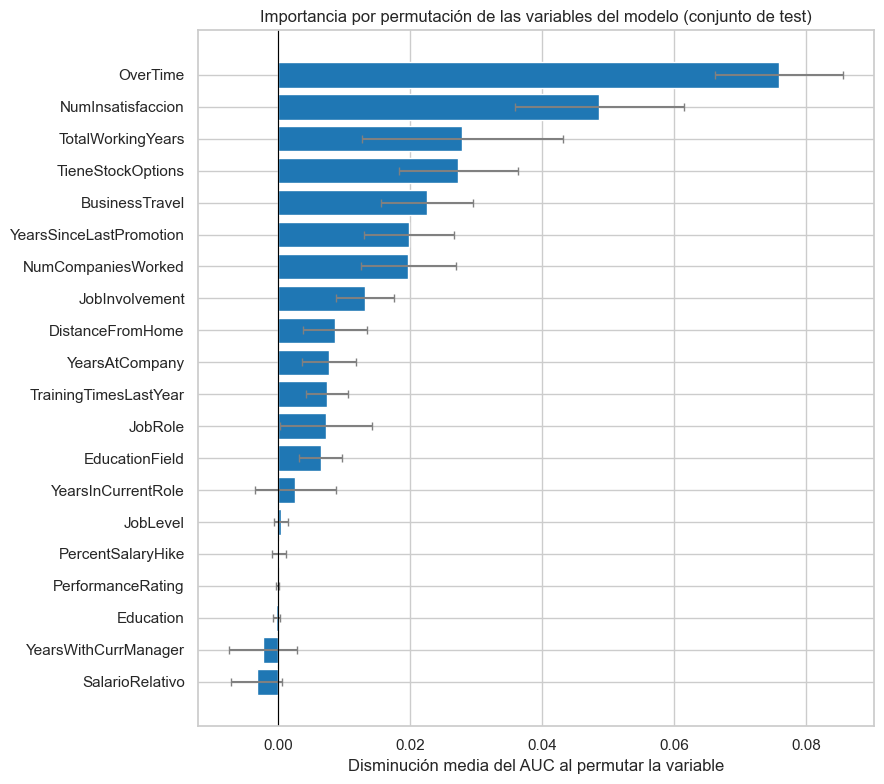

In [94]:
orden_imp = importancias_modelo.sort_values('caida_auc_media')

fig, ax = plt.subplots(figsize=(9, 8))
ax.barh(orden_imp.index, orden_imp['caida_auc_media'], xerr=orden_imp['desviacion'],
        color='tab:blue', ecolor='grey', capsize=3)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('Disminución media del AUC al permutar la variable')
ax.set_title('Importancia por permutación de las variables del modelo (conjunto de test)')
plt.tight_layout()
plt.savefig(FIG_DIR / '12_importancia_variables_modelo.png', dpi=150, bbox_inches='tight')
plt.show()

**Resultado:**

Al permutar directamente las variables que utiliza el modelo, el salario relativo obtiene una importancia prácticamente nula (−0,003), lo que confirma que la elevada importancia de `MonthlyIncome` en el primer cálculo se debía a la extrapolación y no a una contribución real. Este resultado es coherente con los odds ratios, donde el salario relativo no alcanzaba la significación estadística. El resto de variables obtiene los mismos valores en ambos cálculos.

| Grupo | Variables | Disminución del AUC |
|---|---|---|
| Muy importantes | `OverTime`, `NumInsatisfaccion` | 0,076 y 0,049 |
| Importantes | `TotalWorkingYears`, `TieneStockOptions`, `BusinessTravel`, `YearsSinceLastPromotion`, `NumCompaniesWorked` | entre 0,020 y 0,028 |
| Contribución menor | `JobInvolvement`, `DistanceFromHome`, `YearsAtCompany`, `TrainingTimesLastYear`, `JobRole`, `EducationField` | entre 0,006 y 0,013 |
| Sin contribución | `YearsInCurrentRole`, `JobLevel`, `PercentSalaryHike`, `PerformanceRating`, `Education`, `YearsWithCurrManager`, `SalarioRelativo` | inferior a 0,003 o negativa |

- **Las horas extra son la variable más importante del modelo**: al permutarlas, el AUC cae de 0,824 a unos 0,75. Coincide con el mayor odds ratio del modelo, lo que convierte a esta variable en el resultado más sólido del análisis.
- **El indicador de insatisfacción es la segunda variable más importante.** Según el primer cálculo, la escala que más contribuye es la satisfacción con el puesto (0,019), seguida de la satisfacción con el entorno (0,012), con las relaciones (0,007) y la conciliación (0,005).
- **Las variables más importantes coinciden con los efectos significativos de los odds ratios.** Las dos discrepancias son explicables: `YearsWithCurrManager`, significativa en los odds ratios, no aporta capacidad predictiva en el test, probablemente porque comparte información con las demás variables de antigüedad; y `JobRole` tiene una importancia global baja, ya que los puestos con efectos más marcados agrupan a pocos empleados.
- **Las variables sensibles excluidas obtienen una importancia exactamente nula**, lo que confirma que el modelo no utiliza el sexo, el estado civil ni la edad.

**Factores accionables.** De las siete variables más importantes, cinco corresponden a condiciones sobre las que la empresa puede actuar: las horas extra, la satisfacción, las stock options, la frecuencia de viajes y los ascensos. Las otras dos, la experiencia total y el número de empresas anteriores, son características del empleado que no pueden modificarse, pero ayudan a identificar los perfiles de mayor riesgo.

## 6. Aplicación: simulación de bajas esperadas mediante Montecarlo

Las probabilidades individuales del modelo permiten estimar no solo el riesgo de cada empleado, sino también el número total de bajas esperado en un grupo y su coste. Para ello se aplica una simulación de Montecarlo sobre los 441 empleados del conjunto de test: en cada simulación, cada empleado abandona o no la empresa de forma aleatoria según su probabilidad estimada, y se cuentan las bajas resultantes. El proceso se repite 10.000 veces, lo que proporciona la distribución completa del número de bajas y permite calcular un intervalo que recoge el 90 % de los resultados simulados.

Este análisis tiene un doble objetivo:
- **Validar las probabilidades a nivel agregado**: si el modelo está bien calibrado, el número real de bajas del test debería situarse dentro del intervalo simulado, tanto en el total como en cada departamento.
- **Traducir el modelo a términos de gestión**: el número de bajas esperado por departamento y el coste económico asociado, calculado como el 20 % del salario anual de cada empleado que se va.

La simulación solo es válida porque el modelo está calibrado: con probabilidades infladas (por ejemplo, entrenando con reponderación de clases), el número de bajas simulado sería muy superior al real. Debe tenerse en cuenta, además, que se asume que las bajas son independientes entre sí, y que, al no indicar el dataset el periodo en que se produjeron, los resultados se refieren a un grupo de empleados de características similares y no a un horizonte temporal concreto.

In [95]:
rng = np.random.default_rng(config['project']['random_state'])
n_sim = 10_000
yt = y_test.to_numpy()

# Cada fila es una simulación y cada columna un empleado del test:
# True si el empleado "se va" en esa simulación
simulaciones = rng.random((n_sim, len(prob_test))) < prob_test
bajas_sim = simulaciones.sum(axis=1)

inf, sup = np.percentile(bajas_sim, [5, 95])
print(f'Bajas esperadas: {bajas_sim.mean():.1f} | Intervalo del 90 %: {inf:.0f}–{sup:.0f}')
print(f'Bajas reales en el test: {yt.sum()}')
print(f'Porcentaje de simulaciones con menos bajas que las reales: {(bajas_sim < yt.sum()).mean() * 100:.0f} %')

Bajas esperadas: 67.9 | Intervalo del 90 %: 58–78
Bajas reales en el test: 71
Porcentaje de simulaciones con menos bajas que las reales: 68 %


In [96]:
# El departamento se eliminó de las variables del modelo, pero se recupera del dataset original
departamento = df.loc[X_test.index, 'Department'].to_numpy()

filas_dep = []
for dep in np.unique(departamento):
    m = departamento == dep
    bajas_dep = simulaciones[:, m].sum(axis=1)
    filas_dep.append({
        'departamento': dep,
        'empleados': int(m.sum()),
        'bajas_esperadas': bajas_dep.mean(),
        'IC90_inf': np.percentile(bajas_dep, 5),
        'IC90_sup': np.percentile(bajas_dep, 95),
        'bajas_reales': int(yt[m].sum()),
    })

por_departamento = pd.DataFrame(filas_dep).set_index('departamento').round(1)
por_departamento

,empleados,bajas_esperadas,IC90_inf,IC90_sup,bajas_reales
departamento,,,,,
Human Resources,19,3.0,1.0,5.0,3
Research & Development,293,37.5,30.0,45.0,44
Sales,129,27.4,22.0,33.0,24


Coste esperado: 651,223 | Intervalo del 90 %: 529,534–784,461
Coste real de las bajas del test: 791,549


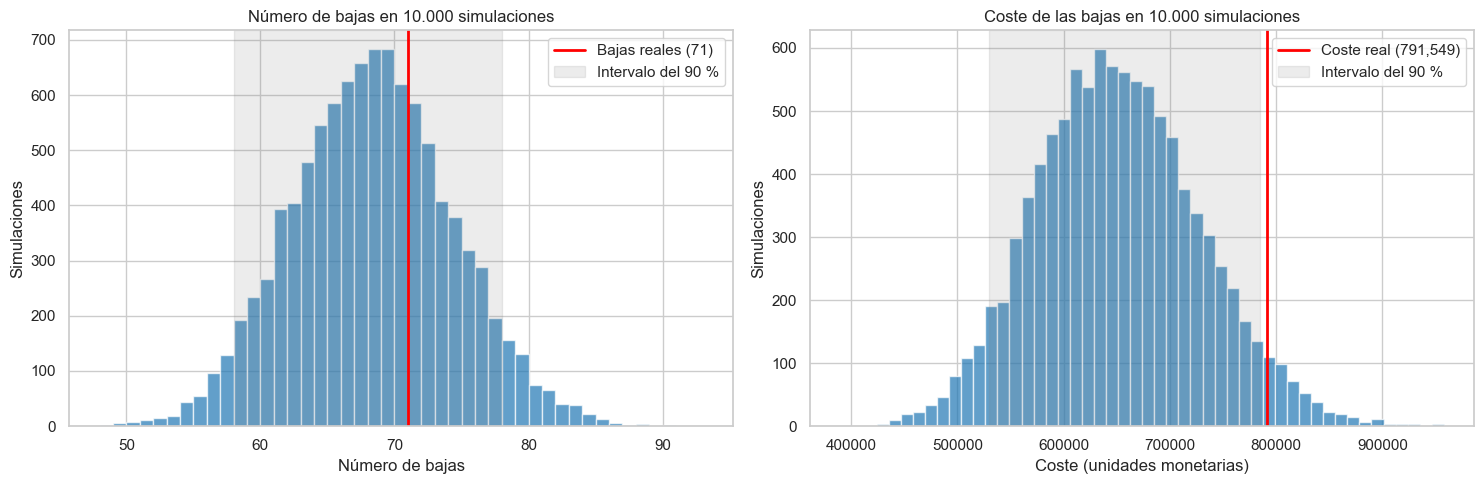

In [97]:
# Coste de cada baja: 20 % del salario anual del empleado
coste_emp = cu['pct_salario_anual'] * 12 * X_test['MonthlyIncome'].to_numpy()
coste_sim = simulaciones @ coste_emp
coste_real = coste_emp[yt == 1].sum()

c_inf, c_sup = np.percentile(coste_sim, [5, 95])
print(f'Coste esperado: {coste_sim.mean():,.0f} | Intervalo del 90 %: {c_inf:,.0f}–{c_sup:,.0f}')
print(f'Coste real de las bajas del test: {coste_real:,.0f}')

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].hist(bajas_sim, bins=range(bajas_sim.min(), bajas_sim.max() + 2), color='tab:blue', alpha=0.7)
axes[0].axvline(yt.sum(), color='red', linewidth=2, label=f'Bajas reales ({yt.sum()})')
axes[0].axvspan(inf, sup, color='grey', alpha=0.15, label='Intervalo del 90 %')
axes[0].set_title('Número de bajas en 10.000 simulaciones')
axes[0].set_xlabel('Número de bajas')
axes[0].set_ylabel('Simulaciones')
axes[0].legend()

axes[1].hist(coste_sim, bins=50, color='tab:blue', alpha=0.7)
axes[1].axvline(coste_real, color='red', linewidth=2, label=f'Coste real ({coste_real:,.0f})')
axes[1].axvspan(c_inf, c_sup, color='grey', alpha=0.15, label='Intervalo del 90 %')
axes[1].set_title('Coste de las bajas en 10.000 simulaciones')
axes[1].set_xlabel('Coste (unidades monetarias)')
axes[1].set_ylabel('Simulaciones')
axes[1].legend()

plt.tight_layout()
plt.savefig(FIG_DIR / '13_simulacion_montecarlo.png', dpi=150, bbox_inches='tight')
plt.show()

**Resultado:**

| | Esperado | Intervalo del 90 % | Real |
|---|---|---|---|
| **Total de bajas** | 67,9 | 58–78 | 71 |
| Human Resources (19 empleados) | 3,0 | 1–5 | 3 |
| Research & Development (293) | 37,5 | 30–45 | 44 |
| Sales (129) | 27,4 | 22–33 | 24 |
| **Coste de las bajas** | 651.223 | 529.534–784.461 | 791.549 |

- **El modelo estima correctamente el número de bajas.** La simulación predice una media de 67,9 bajas en el conjunto de test, con un intervalo del 90 % entre 58 y 78, y se produjeron 71. El valor real se sitúa en la zona central de la distribución (el 68 % de las simulaciones arrojan un número menor), lo que confirma que las probabilidades están bien calibradas también a nivel agregado.
- **Por departamento**, el número real de bajas se encuentra dentro del intervalo simulado en los tres casos. En *Research & Development* se sitúa cerca del límite superior (44 frente a 37,5 esperadas), mientras que en *Sales* es algo menor de lo esperado (24 frente a 27,4) y en *Human Resources* coincide exactamente (3).
- **El coste real supera ligeramente el límite superior del intervalo** (791.549 frente a un máximo de 784.461 y un valor esperado de 651.223), a pesar de que el número de bajas es cercano al esperado. Es decir, el modelo acierta en cuántos empleados se van, pero quienes se fueron tenían salarios más altos de lo previsto. Esto es coherente con el análisis de calibración (apartado 4.4), donde el modelo infraestimaba ligeramente el riesgo en los grupos de menor riesgo, compuestos en mayor medida por empleados con más experiencia y salarios más elevados. Dado que el coste de cada baja es proporcional al salario, unas pocas salidas inesperadas de perfiles senior elevan de forma notable el coste total: un modelo calibrado en el número de bajas no lo está necesariamente en su coste.

**Utilidad para la gestión.** Este análisis permite trasladar las predicciones individuales a magnitudes que facilitan la planificación de RRHH: cuántas bajas cabe esperar en cada departamento, con qué margen de incertidumbre y con qué coste. Los resultados deben interpretarse con las limitaciones señaladas: se asume que las bajas son independientes y, al desconocerse el periodo que recogen los datos, las estimaciones se refieren a un grupo de empleados de características similares y no a un horizonte temporal concreto.

## 7. Conclusiones

### 7.1. Resultados del modelo

Se ha desarrollado un modelo de regresión logística para predecir la probabilidad de que un empleado abandone la empresa. El modelo final, seleccionado entre siete variantes mediante validación cruzada, incorpora tres variables construidas a partir del análisis exploratorio (salario relativo a la mediana del nivel, indicador de insatisfacción e indicador de stock options), aplica una transformación logarítmica a las variables de antigüedad y experiencia y excluye las variables sensibles (sexo, estado civil y edad).

| Métrica | Validación cruzada | Test |
|---|---|---|
| AUC | 0,865 | 0,824 |
| Brier score | 0,084 | 0,098 |
| *Recall* (umbral 0,23) | 0,76 | 0,70 |
| Precisión (umbral 0,23) | 0,52 | 0,49 |
| Especificidad (umbral 0,23) | — | 0,86 |
| Empleados con alarma | 24 % | 23 % |

Con el umbral de 0,23, elegido mediante un análisis de costes, el modelo detecta el 70 % de las bajas del conjunto de test (50 de 71), y aproximadamente una de cada dos alarmas corresponde a un empleado que efectivamente se va, una concentración tres veces superior a la de un grupo elegido al azar. Su accuracy (83,4 %) es inferior a la de predecir que nadie se va (83,9 %), lo que ilustra que esta métrica no es adecuada con clases desbalanceadas: la predicción trivial no detectaría ninguna baja.

Las probabilidades del modelo están bien calibradas, gracias a haber tratado el desbalanceo mediante el umbral y no mediante la reponderación de clases. La simulación de Montecarlo confirma que el número de bajas estimado (67,9; intervalo del 90 %: 58–78) es coherente con el observado (71), tanto en el total como en cada departamento.

Además, el proceso de modelado ha permitido extraer conclusiones metodológicas:
- Las nuevas variables mejoran el modelo de forma consistente frente a las variables originales y corrigen la colinealidad entre el salario y el nivel jerárquico.
- Excluir las variables sensibles no reduce la capacidad predictiva.
- El umbral elegido es robusto ante distintos supuestos sobre la eficacia de la intervención: obtiene entre el 80 % y el 100 % del ahorro máximo en todos los escenarios analizados, con un número de conversaciones asumible.

### 7.2. Factores asociados a la rotación

Combinando los odds ratios y la importancia por permutación, los factores con mayor influencia en la probabilidad de baja son:

1. **Las horas extra**: es el factor más importante y más sólido del análisis. Multiplican las *odds* de baja por 7,7.
2. **La insatisfacción**: cada dimensión adicional (entorno, puesto, relaciones o conciliación) en el nivel más bajo multiplica las *odds* por 3,3. La satisfacción con el puesto es la dimensión que más contribuye.
3. **La ausencia de stock options**: tenerlas reduce las *odds* de baja en un 80 %.
4. **La etapa de la carrera profesional**: el riesgo es mayor en los empleados con menos experiencia total y, a igual antigüedad, en quienes llevan más años sin ascender.
5. **Otros factores**: los viajes frecuentes, el número de empresas anteriores, la baja implicación en el puesto, la menor formación recibida y la distancia al domicilio.

Por el contrario, una vez considerados los factores anteriores, no se relacionan con la baja el sexo, el nivel educativo, la evaluación del desempeño ni la subida salarial. Tampoco el puesto de *Sales Representative*, cuya elevada tasa de bajas se explica por el perfil de sus empleados, más jóvenes y con menos experiencia. El salario relativo muestra el efecto esperado, pero sin alcanzar la significación estadística.

El análisis multivariante ha corregido además conclusiones del análisis de variables por separado. El caso más claro es el de los años desde el último ascenso, cuyo efecto aparente se invertía al no tener en cuenta la antigüedad.

### 7.3. Recomendaciones para RRHH

Los resultados identifican asociaciones y no relaciones causales, por lo que las siguientes recomendaciones deben entenderse como líneas de actuación prioritarias que conviene validar en la práctica:

1. **Revisar la carga de horas extra**, principal factor de riesgo, y analizar en qué puestos y equipos se concentra.
2. **Detectar la insatisfacción de forma temprana** mediante encuestas periódicas, prestando especial atención a los empleados que se sitúan en el nivel más bajo en alguna dimensión, en particular en la satisfacción con el puesto.
3. **Revisar la política de stock options y retribución a largo plazo.** Además de su asociación con la permanencia, el análisis revela que ningún empleado soltero dispone de opciones, por lo que conviene revisar los criterios de asignación desde el punto de vista de la equidad.
4. **Reforzar el desarrollo profesional** de los empleados en las primeras etapas de su carrera y de quienes acumulan varios años sin ascender, incluyendo planes de carrera y acceso a formación.
5. **Utilizar el modelo para priorizar conversaciones de permanencia.** Con el umbral de 0,23, se señalaría aproximadamente a uno de cada cuatro empleados. Si la experiencia demuestra que estas conversaciones son eficaces, sería recomendable extenderlas progresivamente a toda la plantilla, utilizando el modelo para decidir el orden. Registrar los resultados de estas intervenciones permitiría además estimar su eficacia real y ajustar el umbral.
6. **Utilizar las estimaciones agregadas para la planificación**: el número de bajas esperado por departamento, con su margen de incertidumbre, puede orientar la planificación de plantilla y la asignación de recursos de retención.

### 7.4. Consideraciones éticas

El modelo se ha construido sin utilizar el sexo, el estado civil ni la edad, sin pérdida de capacidad predictiva. No obstante, algunas variables actúan como *proxies* parciales de ellas: la experiencia total está relacionada con la edad, y las stock options con el estado civil. Su uso debe supervisarse para evitar efectos discriminatorios indirectos.

Las alarmas del modelo deben activar medidas de apoyo y nunca decisiones negativas sobre el empleado, como reducir su formación o su acceso a proyectos, ya que podrían provocar precisamente la salida que se pretende evitar. El modelo debe servir de apoyo a la decisión de las personas responsables, no sustituirla, y su uso debe comunicarse con transparencia a la plantilla. En la normativa europea, los sistemas de inteligencia artificial utilizados en la gestión de trabajadores se consideran de alto riesgo y requieren supervisión humana.

### 7.5. Limitaciones y líneas futuras

**Limitaciones:**
- El dataset es ficticio, creado por IBM con fines formativos, por lo que los resultados ilustran la metodología pero no pueden generalizarse a una organización real.
- Se desconoce el periodo en que se produjeron las bajas y el momento en que se registraron las variables. Algunas, como los años con el responsable actual, podrían reflejar la situación en el momento de la salida más que anticiparla.
- **El modelo no distingue el valor de los empleados que se van.** Para la empresa no tiene el mismo impacto la salida de un empleado clave (rotación disfuncional) que la de un empleado con bajo rendimiento, que puede resultar incluso beneficiosa (rotación funcional). La única variable de desempeño disponible, `PerformanceRating`, solo toma dos valores (3 y 4) y no muestra relación con la baja, por lo que no permite identificar el talento clave. El análisis de costes utiliza el salario como aproximación al valor de cada empleado, pero el salario refleja sobre todo el nivel y la experiencia, no necesariamente el rendimiento.
- `NumCompaniesWorked` presenta incoherencias en el 16,6 % de los registros.
- El conjunto de test contiene solo 71 bajas, por lo que sus métricas están sujetas a una variabilidad considerable.
- Los costes y la eficacia de la intervención se basan en supuestos, aunque el análisis de sensibilidad muestra que la decisión es robusta.
- El modelo infraestima ligeramente el riesgo en los grupos de menor riesgo, lo que se traduce en una infraestimación del coste de las bajas de perfiles senior.

**Líneas futuras:**
- **Priorizar según el valor del empleado.** Disponer de una medida fiable del desempeño o del valor de cada empleado (evaluaciones con mayor rango, objetivos alcanzados, potencial o criticidad del puesto) permitiría priorizar las acciones de retención según la pérdida esperada, es decir, la probabilidad de baja multiplicada por el valor del empleado, y no solo según la probabilidad. Los empleados con alto riesgo y alto valor serían la prioridad de la dirección, mientras que en los de alto riesgo y bajo valor podrían plantearse otro tipo de actuaciones. Este enfoque requeriría definir criterios de valoración transparentes y objetivos, para no introducir sesgos en la evaluación de las personas.
- Aplicar la metodología a datos reales con fechas de alta y baja, lo que permitiría modelos de supervivencia que estimen no solo si un empleado se irá, sino cuándo.
- Evaluar la eficacia real de las conversaciones de permanencia mediante un piloto, para sustituir los supuestos por datos.
- Comparar con modelos capaces de recoger relaciones no lineales e interacciones, como los conjuntos de árboles, evaluando si una posible mejora en la predicción compensa la pérdida de interpretabilidad.
- Reentrenar y recalibrar el modelo periódicamente, y analizar sus resultados por grupos de empleados para verificar que no genera efectos discriminatorios.